<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/18_Cloud_Virtual_Environment_Threats/HybridQNN_VMIThreatDetection_Tripathi2023.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid quantum neural network for virtual-machine threat detection: Tripathi, Upadhyay and Soni (2023) step by step

**Paper.** S. M. Tripathi, H. Upadhyay and J. Soni, *Quantum Neural Network Classification-Based Cyber Threat Detection in Virtual Environment*, 2023 International Conference on Computational Science and Computational Intelligence (CSCI), pp. 391-395, IEEE, 2023. DOI: [10.1109/CSCI62032.2023.00070](https://doi.org/10.1109/CSCI62032.2023.00070).

**What this notebook does.** The paper classifies *processes* of a virtual machine as benign or malicious from four memory-introspection attributes. A small hybrid network (`Dense(4)` -> PennyLane variational quantum layer with angle embedding and `StronglyEntanglingLayers` -> `Dense(1)`) is trained for 4 to 12 qubits and the test precision / recall / F1 / accuracy are tabulated (paper Table II, Fig. 7, Figs. 8-13). This notebook rebuilds that pipeline, trains the same family of models for 4 to 12 qubits, trains classical baselines on exactly the same inputs, and ends with an honest side-by-side comparison with the paper's numbers.

**Important: the paper's data are private.** The authors captured process attributes on their own Xen/LibVMI/DRAKVUF testbed after injecting a custom DLL; that dataset is not published. This notebook therefore uses the public **CIC-MalMem-2022** memory-forensics dataset (Volatility-derived features of Windows memory dumps, balanced benign / malware) as a *substitute*, mapping each of the paper's four attributes to the closest available Volatility feature. Absolute numbers are therefore **not expected to match** the paper; the qualitative claims (accuracy versus number of qubits, comparison with classical models) are what can be tested. All of this is documented below.

**How to run.** Open in Google Colab, choose a **CPU** runtime, and use *Runtime -> Run all*. With `FAST_MODE = True` (8,000 records, 3 epochs, 1 seed) the whole notebook takes about 6-15 minutes on a laptop CPU, depending on load; with `FAST_MODE = False` it uses 35,400 records, 10 epochs (the axis of the paper's Figs. 8-13) and 3 seeds for 4-8 qubits (1 seed for 9-12 qubits), which takes several hours on a busy laptop CPU (the 11- and 12-qubit simulations dominate; training runs are cached, so an interrupted session resumes). **The outputs stored in this notebook come from a complete `FAST_MODE = True` run**; a full run was started but not finished on the authoring machine (see the report in the repository log). The dataset is public on the Hugging Face Hub (no token needed); if you ever hit a rate limit, add your own token as the Colab secret `HF_TOKEN` (the notebook reads it only from the environment or Colab Secrets and never prints it).

**At the end you get:** the Table II analogue for 4-12 qubits (mean +/- std over seeds), the accuracy-versus-qubits figure, training / validation curves, confusion matrices, quantum versus classical timing, and a per-claim verdict table.

## The paper in one page

* **Problem.** Detect malware-infected processes inside virtual machines with *Virtual Machine Introspection* (VMI): the hypervisor reads the kernel `_EPROCESS` structure of each process from outside the guest. The hypothesis is that an injected malicious DLL changes process attributes, so detection becomes a **binary classification** (benign / malicious) of process feature vectors.
* **Data (private).** Xen 4.12 + libvirt 5.4, attributes read with LibVMI / DRAKVUF and Rekall profiles; malicious processes created by custom DLL injection. Four attributes were used: **Peak Virtual Size, Active Threads High Watermark, Commit Charge, VAD Count**. Classes "almost equal" in size. The Keras summary in the paper shows an input of shape (28320, 4).
* **Preprocessing.** MinMax scaling of the four attributes.
* **Model (Fig. 6).** Hybrid network on PennyLane's `default.qubit` simulator: a Dense layer, a `KerasLayer` (angle embedding of the inputs, a strongly-entangling variational block, one Pauli-Z expectation per qubit) and a final Dense layer with one output. Trained with TensorFlow, **4 to 12 qubits**.
* **Metrics.** Precision, recall, F1 on test data (Table II) and accuracy (Fig. 7); training / validation accuracy and loss versus epoch (Figs. 8-13, 10 epochs on the axis).
* **Claims checked here.** (1) Table II: for 4-8, 10 and 12 qubits all metrics are about 0.92-0.94 (4 qubits: P 0.941, R 0.940, F1 0.939; 12 qubits: 0.917 / 0.918 / 0.917). (2) At 9 and 11 qubits the model collapses (accuracy 0.517, macro precision 0.258, F1 about 0.34). (3) Fig. 7: accuracy about 0.93-0.94 for most settings, 0.939 at 4 and 7 qubits, 0.91 at 12 qubits. (4) Best results when the number of qubits equals or is close to the number of features (4). (5) The quantum model reaches accuracy "comparable to the classical methods" but takes longer.

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | Private Xen/LibVMI process attributes (DLL injection) | Public **CIC-MalMem-2022** (58,596 memory-dump records, Volatility features), substitute |
| The 4 attributes | Peak Virtual Size, Active Threads High Watermark, Commit Charge, VAD Count | Nearest Volatility analogues: `dlllist.ndlls` (mapped images ~ virtual size), `pslist.avg_threads` (threads), `malfind.commitCharge` (commit charge), `handles.nsection` (section objects ~ VAD-mapped regions). Fixed a priori, not selected on accuracy |
| Unit of observation | One process | One memory dump (aggregate over its processes) |
| Sample size | Input (28320, 4), implied training set | 35,400 class-balanced records: 28,320 train+validation, 7,080 test |
| Scaling | MinMax | `MinMaxScaler` fitted on the training split only, test clipped to [0, 1] |
| Network | Dense, KerasLayer, Dense(1) | `Linear(4,4)` -> quantum layer -> `Linear(n,1)` (sigmoid inside the loss) `# CHOICE:` |
| Quantum layer | AngleEmbedding + StronglyEntanglingLayers, n qubits | Same; the 4 inputs go on wires 0-3, the other wires start in the zero state `# CHOICE:` |
| Number of layers | not stated | 2 `# CHOICE:` |
| Framework | PennyLane + TensorFlow/Keras `KerasLayer` | PennyLane + **PyTorch** (`KerasLayer` no longer exists in PennyLane 0.45 / Keras 3), exact torch statevector twin of the QNode for speed, checked against PennyLane `# CHOICE:` |
| Optimiser, learning rate, batch size | not stated | Adam, lr 0.02, batch 512 (256 in fast mode) `# CHOICE:` |
| Epochs | about 10 (x-axis of Figs. 8-13) | 10 (full) / 3 (fast) |
| Validation | curves shown, split not stated | 10% of the training split, used for the curves only |
| Averaging of P / R / F1 | not stated | **macro** (this reproduces the paper's collapse row: macro precision 0.258 = 0.517 / 2) |
| Seeds | one run implied | 3 seeds for 4-8 qubits and 1 seed for 9-12 qubits (full, CPU cost) / 1 (fast), mean +/- std |
| Classical comparison | "comparable to classical methods", no numbers | RandomForest, SVC (rbf), logistic regression on the same 4 inputs, plus a classical twin of the hybrid net (quantum layer replaced by `Linear(4,n)+tanh`), plus RF / SVC on all 55 features |

In [1]:
# Installs, pinned to the versions this notebook was tested with. Skipped when the packages already exist (local runs).
import sys, importlib
IN_COLAB = "google.colab" in sys.modules
try:
    import pennylane, torch, huggingface_hub  # noqa: F401
    NEED_INSTALL = False
except Exception:
    NEED_INSTALL = True
if IN_COLAB or NEED_INSTALL:
    !pip -q install "pennylane==0.45.1" huggingface_hub   # torch, numpy, pandas, scikit-learn, matplotlib ship with Colab
    print("Installed. If imports below fail, use Runtime -> Restart session and run again.")
else:
    print("Packages already available; nothing to install.")


Packages already available; nothing to install.


In [2]:
# ---------------- Configuration: every tunable constant lives here ----------------
SEED = 42
FAST_MODE = True            # True: 8,000 records, 3 epochs, 1 seed (about 6 min); False: 35,400 records, 10 epochs, 3 seeds for 4-8 qubits, 1 seed for 9-12 (several hours on a busy laptop CPU)
DATA_DIR = "malmem_data"    # downloaded files are cached here
DATA_PATH = ""              # optional: path of your own MalMem2022.csv (skips the download)

# Paper-like settings (CHOICE: where the paper is silent)
N_LAYERS = 2                # StronglyEntanglingLayers depth
N_FEATURES = 4              # the four process attributes
LR = 0.02                   # Adam learning rate
BATCH_SIZE = 256 if FAST_MODE else 512   # CHOICE: not stated in the paper; 512 halves the cost of the 12-qubit simulation
TEST_SIZE = 0.20
VAL_FRAC = 0.10             # of the training split, used only for the training/validation curves

if FAST_MODE:
    N_TOTAL, EPOCHS, SEEDS_N, QUBITS = 8_000, 3, 1, [4, 5, 6, 7, 8, 9, 10, 11, 12]
else:
    N_TOTAL, EPOCHS, SEEDS_N, QUBITS = 35_400, 10, 3, [4, 5, 6, 7, 8, 9, 10, 11, 12]
SEEDS = [SEED + i for i in range(SEEDS_N)]
# CHOICE: the 12-qubit simulation is expensive on a CPU, so in the full run the cheap settings (4-8 qubits) use all seeds
# and the expensive ones (9-12 qubits) use the first seed only. Set ALL_SEEDS_EVERYWHERE = True to use every seed everywhere.
ALL_SEEDS_EVERYWHERE = FAST_MODE
SEEDS_BY_QUBIT = {n: (SEEDS if (ALL_SEEDS_EVERYWHERE or n <= 8) else SEEDS[:1]) for n in QUBITS}
print(dict(FAST_MODE=FAST_MODE, N_TOTAL=N_TOTAL, EPOCHS=EPOCHS, SEEDS_BY_QUBIT=SEEDS_BY_QUBIT))


{'FAST_MODE': True, 'N_TOTAL': 8000, 'EPOCHS': 3, 'SEEDS_BY_QUBIT': {4: [42], 5: [42], 6: [42], 7: [42], 8: [42], 9: [42], 10: [42], 11: [42], 12: [42]}}


In [3]:
import os, time, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix
warnings.filterwarnings("ignore")

# Hugging Face token: only needed if the Hub rate-limits you. Read from the environment / Colab Secrets, never printed.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))
def seed_everything(seed):
    np.random.seed(seed); torch.manual_seed(seed)
seed_everything(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| sklearn", sklearn.__version__)
print("torch", torch.__version__, "| pennylane", qml.__version__, "| matplotlib", matplotlib.__version__)


python 3.12.10 | numpy 2.5.4 | pandas 3.0.6 | sklearn 1.9.1
torch 2.14.1+cpu | pennylane 0.45.1 | matplotlib 3.11.2


## 1. Data: the public CIC-MalMem-2022 substitute

CIC-MalMem-2022 (Canadian Institute for Cybersecurity) contains 58,596 records, **29,298 benign and 29,298 malware** (spyware, ransomware, trojans), each described by 55 Volatility-derived features of one memory dump (process list, DLL list, handles, loaded modules, `malfind`, `psxview`, services, callbacks). It is the closest public analogue of the paper's setting: *memory forensics of a Windows machine, balanced benign versus malicious, process-structure attributes*. We download it from public Hugging Face mirrors (cached in `DATA_DIR`).

In [4]:
CANDIDATE_REPOS = ["bvk/CIC-MalMem-2022", "hina-Code/CIC-MalMem-2022", "thousif834/CIC-MalMem-2022"]
FILENAME = "MalMem2022.csv"

def locate_csv():
    if DATA_PATH and os.path.exists(DATA_PATH):
        return DATA_PATH
    local = os.path.join(DATA_DIR, FILENAME)
    if os.path.exists(local):
        return local
    from huggingface_hub import hf_hub_download
    last = None
    for repo in CANDIDATE_REPOS:
        try:
            return hf_hub_download(repo, FILENAME, repo_type="dataset", local_dir=DATA_DIR, token=HF_TOKEN or None)
        except Exception as e:
            last = e; print("mirror failed:", repo, type(e).__name__)
    raise RuntimeError("CIC-MalMem-2022 could not be downloaded; upload MalMem2022.csv and set DATA_PATH") from last

csv_path = locate_csv()
raw = pd.read_csv(csv_path)
print("loaded", csv_path, raw.shape)
raw.head(3)


loaded malmem_data\MalMem2022.csv (58596, 58)


,pslist.nproc,pslist.nppid,pslist.avg_threads,pslist.nprocs64bit,pslist.avg_handlers,dlllist.ndlls,dlllist.avg_dlls_per_proc,handles.nhandles,handles.avg_handles_per_proc,handles.nport,...,svcscan.process_services,svcscan.shared_process_services,svcscan.interactive_process_services,svcscan.nactive,callbacks.ncallbacks,callbacks.nanonymous,callbacks.ngeneric,Class,Category,Filename
0,45,17,10.555556,0,202.844444,1694,38.50000,9129,212.302326,0,...,24,116,0,121,87,0,8,Benign,Benign,Benign
1,47,19,11.531915,0,242.234043,2074,44.12766,11385,242.234043,0,...,24,118,0,122,87,0,8,Benign,Benign,Benign
2,40,14,14.725000,0,288.225000,1932,48.30000,11529,288.225000,0,...,27,118,0,120,88,0,8,Benign,Benign,Benign


## 2. Cleaning, labels, the four attributes, sampling and split

Steps (all fitted on the training split only):

1. Strip column names, drop exact duplicate records (same features and label).
2. Labels: `Class` is `Benign` / `Malware`; malware is the positive class (1). The `Category` column (e.g. `Ransomware-Pysa`) gives the malware **family**, which is kept for the plots.
3. Keep the four attributes that mirror the paper's (see the table above). The mapping is fixed *before* looking at any accuracy.
4. Class-balanced random sample of `N_TOTAL` records, stratified train/test split, a validation part carved from the training split, `MinMaxScaler` fitted on the training part (the paper's preprocessing).

In [5]:
raw.columns = [c.strip() for c in raw.columns]
feature_cols_all = [c for c in raw.columns if c not in ("Class", "Category", "Filename")]
df = raw.drop_duplicates(subset=feature_cols_all + ["Class"]).reset_index(drop=True)
print(f"duplicates removed: {len(raw) - len(df)}  -> {len(df)} records")

# CHOICE: nearest Volatility analogues of the paper's four _EPROCESS attributes
ATTR_MAP = {
    "Peak Virtual Size":                 "dlllist.ndlls",         # number of mapped modules ~ virtual footprint
    "Active Threads High Watermark":     "pslist.avg_threads",    # threads per process
    "Commit Charge":                     "malfind.commitCharge",  # commit charge of suspicious regions
    "VAD Count":                         "handles.nsection",      # section objects ~ VAD-mapped regions
}
FEATS = list(ATTR_MAP.values())
assert len(FEATS) == N_FEATURES

df["y"] = (df["Class"] == "Malware").astype(int)
df["family"] = df["Category"].str.split("-").str[0]
df["subtype"] = df["Category"]

# class-balanced sample (CHOICE: the paper's 28,320-row input implies a balanced set of this size)
per_class = N_TOTAL // 2
sample = (pd.concat([df[df["y"] == k].sample(per_class, random_state=SEED) for k in (0, 1)])
            .sample(frac=1.0, random_state=SEED).reset_index(drop=True))

idx = np.arange(len(sample))
idx_tr_all, idx_te = train_test_split(idx, test_size=TEST_SIZE, stratify=sample["y"], random_state=SEED)
idx_tr, idx_val = train_test_split(idx_tr_all, test_size=VAL_FRAC, stratify=sample["y"].values[idx_tr_all], random_state=SEED)

X_all = sample[FEATS].values.astype(float)
y_all = sample["y"].values
scaler = MinMaxScaler().fit(X_all[idx_tr_all])            # fitted on the training split only (train + validation part)
def prep(ix): return np.clip(scaler.transform(X_all[ix]), 0.0, 1.0)
X_tr, X_val, X_te = prep(idx_tr), prep(idx_val), prep(idx_te)
y_tr, y_val, y_te = y_all[idx_tr], y_all[idx_val], y_all[idx_te]
print("train/val/test:", X_tr.shape, X_val.shape, X_te.shape, "| positives (malware) in test:", int(y_te.sum()), "of", len(y_te))


duplicates removed: 569  -> 58027 records


train/val/test: (5760, 4) (640, 4) (1600, 4) | positives (malware) in test: 800 of 1600


## Dataset Exploration and Visualisation

Everything below uses the real records of CIC-MalMem-2022 and their ground-truth labels. We print the shape, the feature names and the label values, plot the class distribution (binary class and malware family), and draw 2-D scatter plots of the real observations: first the raw PCA coordinates of the four attributes (PCA fitted on the training split), then the same coordinates scaled to [0, pi] as angles.

In [6]:
print("Full dataset (before sampling):", raw.shape)
print("All feature columns (%d):" % len(feature_cols_all)); print(feature_cols_all)
print("\nOriginal label column 'Class':"); print(raw["Class"].value_counts().to_string())
print("\nOriginal 'Category' values (family-subtype):"); print(raw["Category"].value_counts().to_string())
print("\nThe four attributes used (paper attribute -> Volatility feature):"); print(ATTR_MAP)
print("\nSampled set used here:", sample.shape, "| train/val/test =", len(idx_tr), len(idx_val), len(idx_te))
print(sample.loc[idx_tr_all, "family"].value_counts().to_string())
print("\nSummary of the four attributes by class (raw units):")
sample.groupby("Class")[FEATS].describe().T.round(2)


Full dataset (before sampling): (58596, 58)
All feature columns (55):
['pslist.nproc', 'pslist.nppid', 'pslist.avg_threads', 'pslist.nprocs64bit', 'pslist.avg_handlers', 'dlllist.ndlls', 'dlllist.avg_dlls_per_proc', 'handles.nhandles', 'handles.avg_handles_per_proc', 'handles.nport', 'handles.nfile', 'handles.nevent', 'handles.ndesktop', 'handles.nkey', 'handles.nthread', 'handles.ndirectory', 'handles.nsemaphore', 'handles.ntimer', 'handles.nsection', 'handles.nmutant', 'ldrmodules.not_in_load', 'ldrmodules.not_in_init', 'ldrmodules.not_in_mem', 'ldrmodules.not_in_load_avg', 'ldrmodules.not_in_init_avg', 'ldrmodules.not_in_mem_avg', 'malfind.ninjections', 'malfind.commitCharge', 'malfind.protection', 'malfind.uniqueInjections', 'psxview.not_in_pslist', 'psxview.not_in_eprocess_pool', 'psxview.not_in_ethread_pool', 'psxview.not_in_pspcid_list', 'psxview.not_in_csrss_handles', 'psxview.not_in_session', 'psxview.not_in_deskthrd', 'psxview.not_in_pslist_false_avg', 'psxview.not_in_eproces

Class                        Benign    Malware
dlllist.ndlls        count  4000.00    4000.00
                     mean   2082.56    1542.45
                     std     208.77     157.26
                     min     915.00     670.00
                     25%    2000.00    1482.00
                     50%    2085.00    1558.00
                     75%    2153.00    1621.00
                     max    3243.00    3362.00
pslist.avg_threads   count  4000.00    4000.00
                     mean     12.60      10.07
                     std       0.95       0.94
                     min       9.32       2.18
                     25%      12.12       9.60
                     50%      12.83       9.95
                     75%      13.26      10.22
                     max      16.35      16.68
malfind.commitCharge count  4000.00    4000.00
                     mean     10.15    1777.84
                     std      16.85    7318.35
                     min       1.00       1.00
                     25%       5.00       3.00
                     50%       5.00       3.00
                     75%       6.00       4.00
                     max      88.00  176622.00
handles.nsection     count  4000.00    4000.00
                     mean    408.46     171.41
                     std      63.76      39.28
                     min      69.00      50.00
                     25%     382.00     162.00
                     50%     415.00     177.00
                     75%     439.00     181.00
                     max     697.00    1073.00

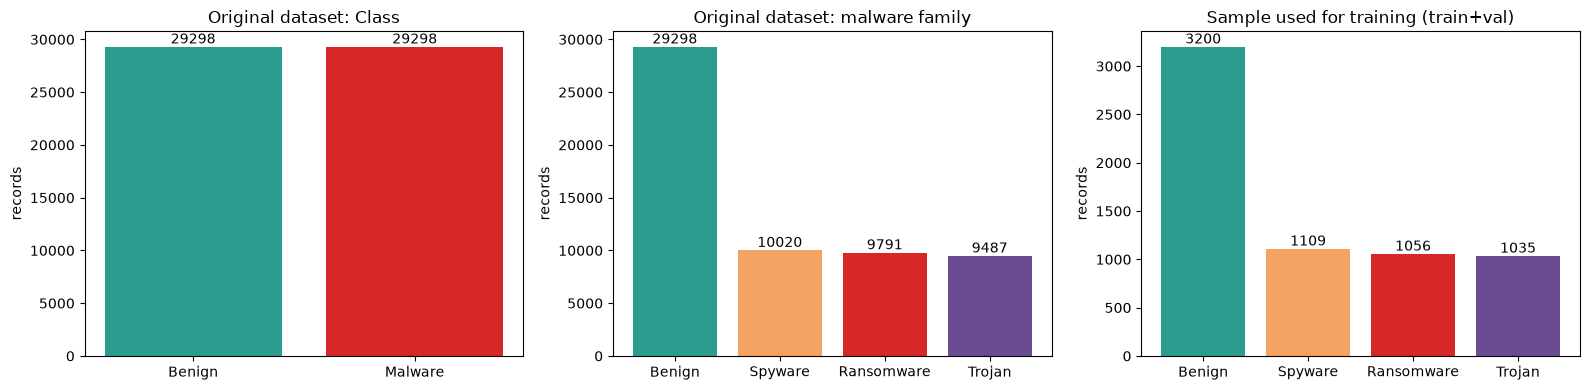

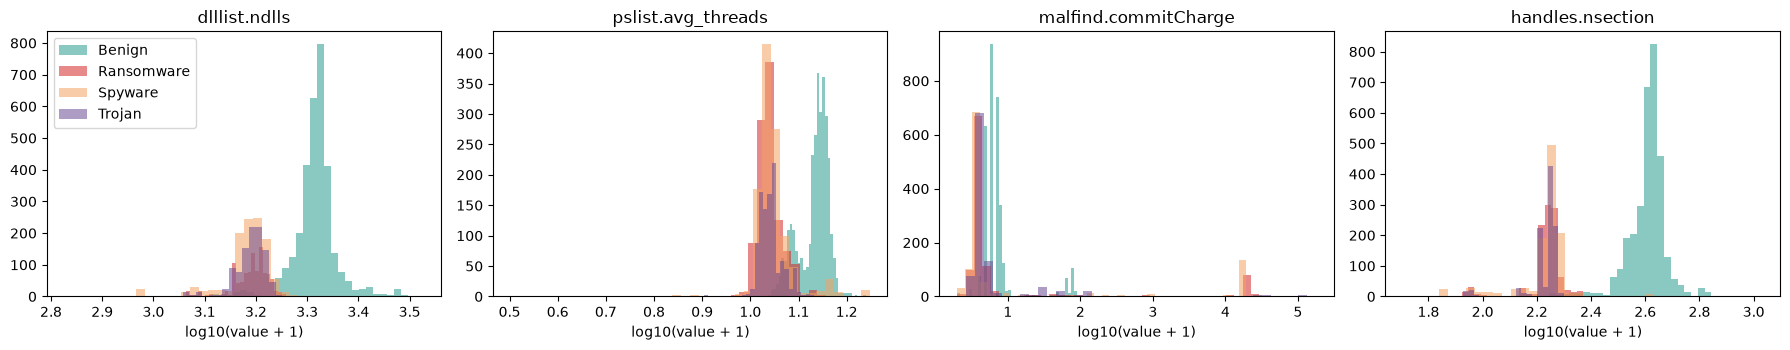

In [7]:
FAMILY_COLORS = {"Benign": "#2a9d8f", "Ransomware": "#d62828", "Spyware": "#f4a261", "Trojan": "#6a4c93"}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
vc = raw["Class"].value_counts(); ax[0].bar(vc.index, vc.values, color=["#2a9d8f", "#d62828"]); ax[0].set_title("Original dataset: Class")
for i, v in enumerate(vc.values): ax[0].text(i, v, str(v), ha="center", va="bottom")
fam = raw["Category"].str.split("-").str[0].value_counts()
ax[1].bar(fam.index, fam.values, color=[FAMILY_COLORS[f] for f in fam.index]); ax[1].set_title("Original dataset: malware family")
for i, v in enumerate(fam.values): ax[1].text(i, v, str(v), ha="center", va="bottom")
sub = sample.loc[idx_tr_all, "family"].value_counts()
ax[2].bar(sub.index, sub.values, color=[FAMILY_COLORS[f] for f in sub.index]); ax[2].set_title("Sample used for training (train+val)")
for i, v in enumerate(sub.values): ax[2].text(i, v, str(v), ha="center", va="bottom")
for a in ax: a.set_ylabel("records")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
for j, f in enumerate(FEATS):
    for fam_name, col in FAMILY_COLORS.items():
        v = sample.loc[idx_tr_all][sample.loc[idx_tr_all, "family"] == fam_name][f]
        ax[j].hist(np.log10(v + 1), bins=40, alpha=0.55, color=col, label=fam_name)
    ax[j].set_title(f); ax[j].set_xlabel("log10(value + 1)")
ax[0].legend(); plt.tight_layout(); plt.show()


explained variance ratio of the 2 components: [0.632 0.244]


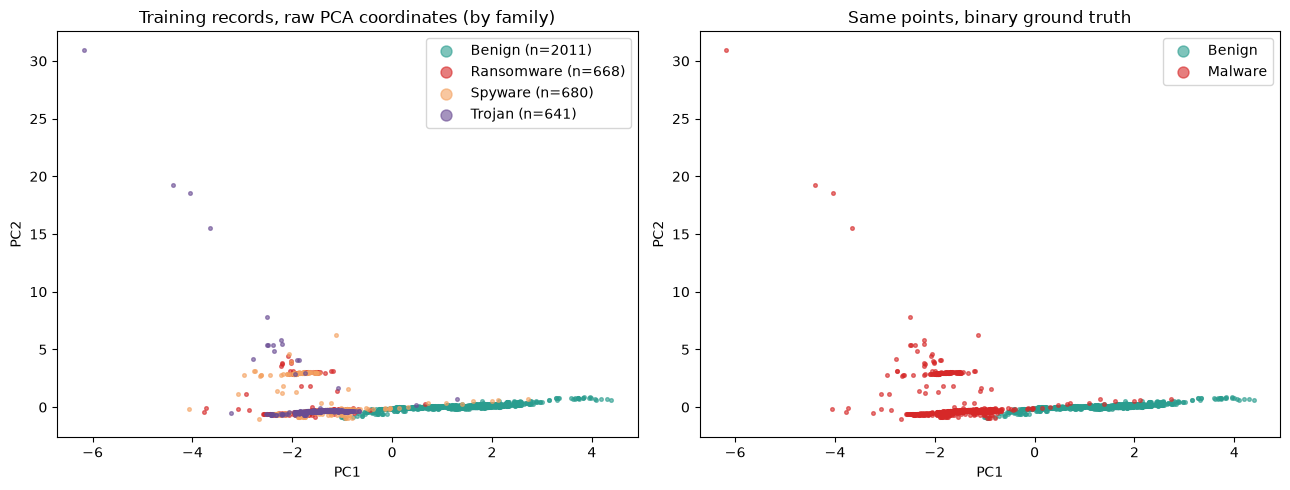

In [8]:
# Scatter 1: raw PCA coordinates (PCA fitted on the training split), every point is a real record coloured by its ground-truth label.
# Standardise first: the raw attributes live on very different scales (commit charge reaches 10^5).
from sklearn.preprocessing import StandardScaler
std = StandardScaler().fit(X_all[idx_tr_all])
pca = PCA(n_components=2, random_state=SEED).fit(std.transform(X_all[idx_tr_all]))
P_tr = pca.transform(std.transform(X_all[idx_tr_all]))
fam_tr = sample.loc[idx_tr_all, "family"].values
print("explained variance ratio of the 2 components:", pca.explained_variance_ratio_.round(3))
sel = rng.choice(len(P_tr), size=min(4000, len(P_tr)), replace=False)       # plot a random subset of real records
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for fam_name, col in FAMILY_COLORS.items():
    m = fam_tr[sel] == fam_name
    ax[0].scatter(P_tr[sel][m, 0], P_tr[sel][m, 1], s=7, alpha=0.6, color=col, label=f"{fam_name} (n={m.sum()})")
ax[0].set_title("Training records, raw PCA coordinates (by family)"); ax[0].set_xlabel("PC1"); ax[0].set_ylabel("PC2"); ax[0].legend(markerscale=3)
for lab, name, col in [(0, "Benign", "#2a9d8f"), (1, "Malware", "#d62828")]:
    m = y_all[idx_tr_all][sel] == lab
    ax[1].scatter(P_tr[sel][m, 0], P_tr[sel][m, 1], s=7, alpha=0.6, color=col, label=name)
ax[1].set_title("Same points, binary ground truth"); ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].legend(markerscale=3)
plt.tight_layout(); plt.show()


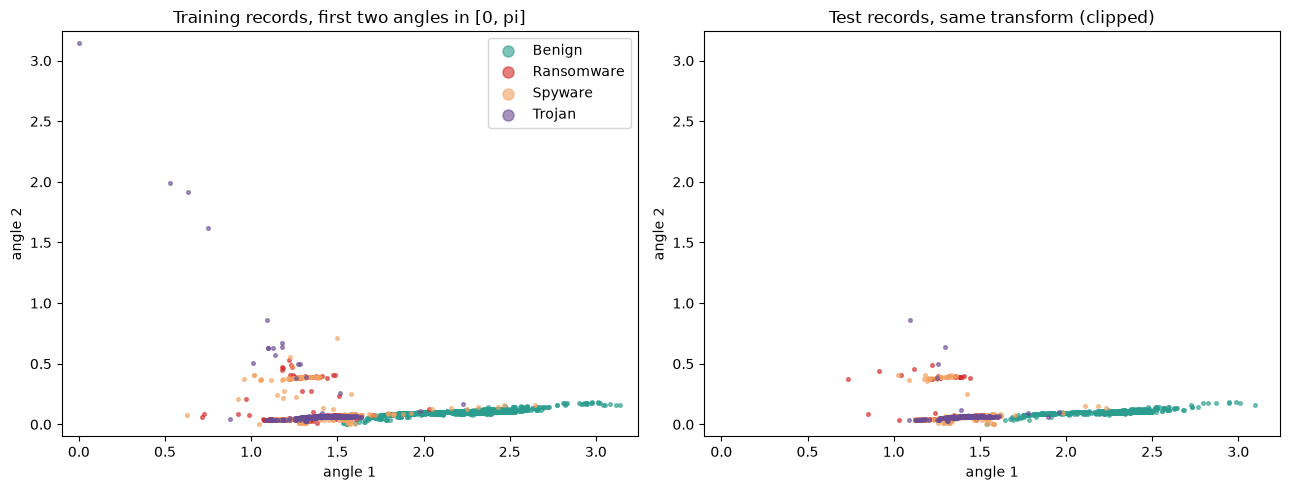

In [9]:
# Scatter 2: the same PCA coordinates scaled to [0, pi] (angle range), fitted on the training split, test angles clipped.
# The paper itself feeds MinMax values in [0, 1] through a Dense(4) layer before the embedding; this plot only shows
# how separable the real classes are in an angle-encoding range.
ang = MinMaxScaler((0, np.pi)).fit(P_tr)
A_tr = ang.transform(P_tr)
P_te = pca.transform(std.transform(X_all[idx_te])); A_te = np.clip(ang.transform(P_te), 0, np.pi)
fam_te = sample.loc[idx_te, "family"].values
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for fam_name, col in FAMILY_COLORS.items():
    m = fam_tr[sel] == fam_name
    ax[0].scatter(A_tr[sel][m, 0], A_tr[sel][m, 1], s=7, alpha=0.6, color=col, label=fam_name)
    m2 = fam_te == fam_name
    ax[1].scatter(A_te[m2, 0], A_te[m2, 1], s=7, alpha=0.6, color=col, label=fam_name)
for a, t in zip(ax, ["Training records, first two angles in [0, pi]", "Test records, same transform (clipped)"]):
    a.set_title(t); a.set_xlabel("angle 1"); a.set_ylabel("angle 2"); a.set_xlim(-0.1, np.pi+0.1); a.set_ylim(-0.1, np.pi+0.1)
ax[0].legend(markerscale=3); plt.tight_layout(); plt.show()


## Quantum Circuit Architecture

The quantum layer of the paper's hybrid model is the PennyLane circuit

* `AngleEmbedding(inputs, wires=0..3)`: the four outputs of the preceding `Dense(4)` layer become rotation angles (rotation `RX`) on wires 0-3. The paper does not say what happens on the extra wires of the 5- to 12-qubit models; we leave them in |0> (`# CHOICE:`), so for `n > 4` the extra qubits take part only through entangling gates.
* `StronglyEntanglingLayers(weights, wires=0..n-1)` with `weights.shape = (N_LAYERS, n, 3)`: per layer, one general rotation `Rot(phi, theta, omega)` per qubit followed by a ring of CNOTs whose range grows with the layer (`# CHOICE:` 2 layers, the paper gives no depth).
* Measurement: the expectation value of Pauli-Z on **every** qubit, returned as an n-vector that feeds the final `Dense(1)`.

Below we draw the PennyLane QNode that is actually used, one drawing per qubit count (each count is a different architecture), and print qubit count, depth and trainable-parameter count.

Matplotlib is building the font cache; this may take a moment.


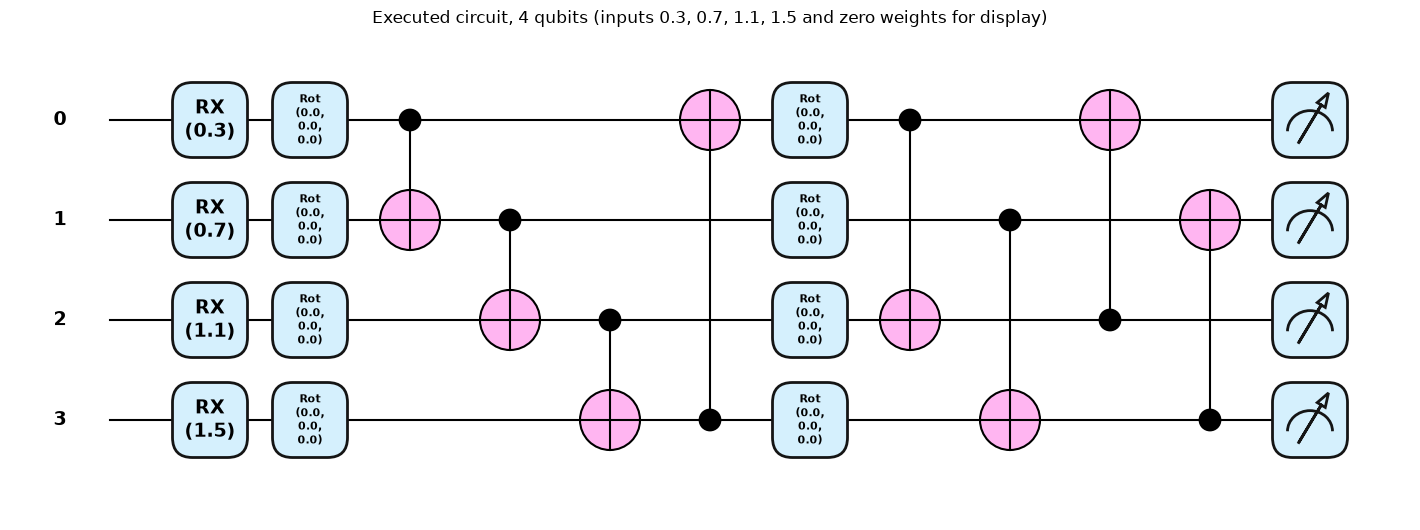

Matplotlib is building the font cache; this may take a moment.


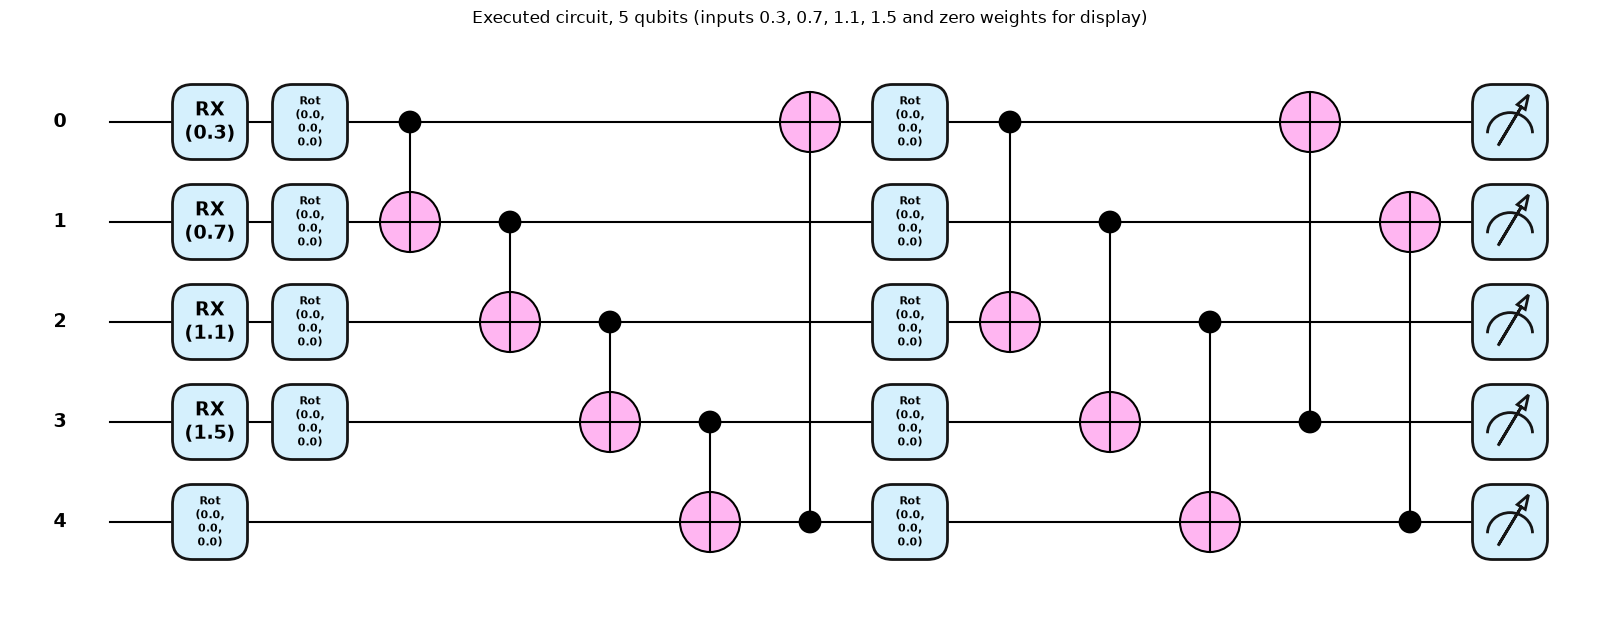

Matplotlib is building the font cache; this may take a moment.


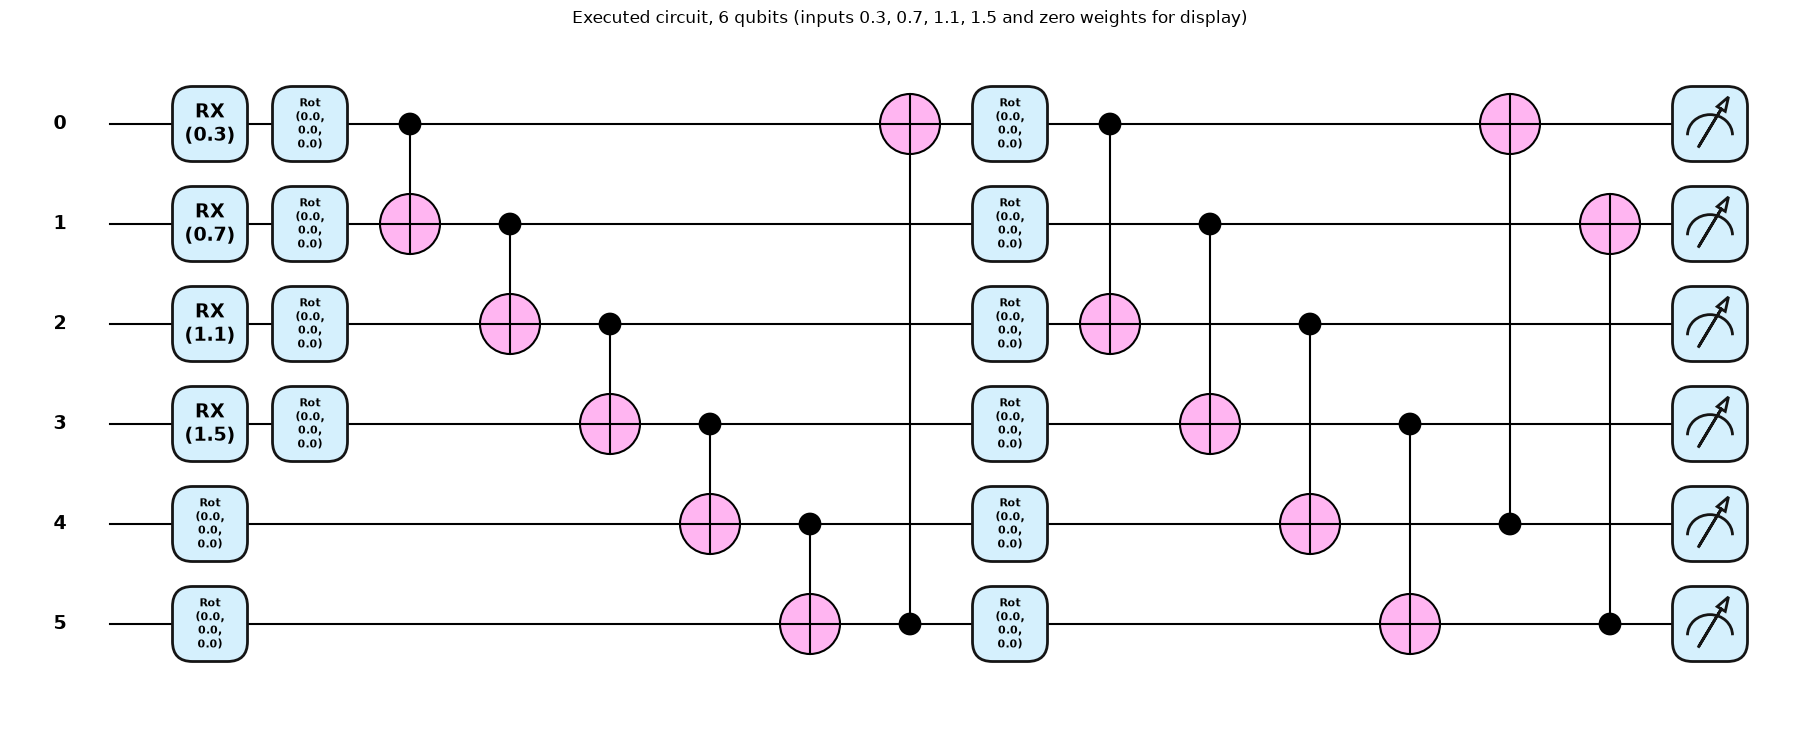

Matplotlib is building the font cache; this may take a moment.


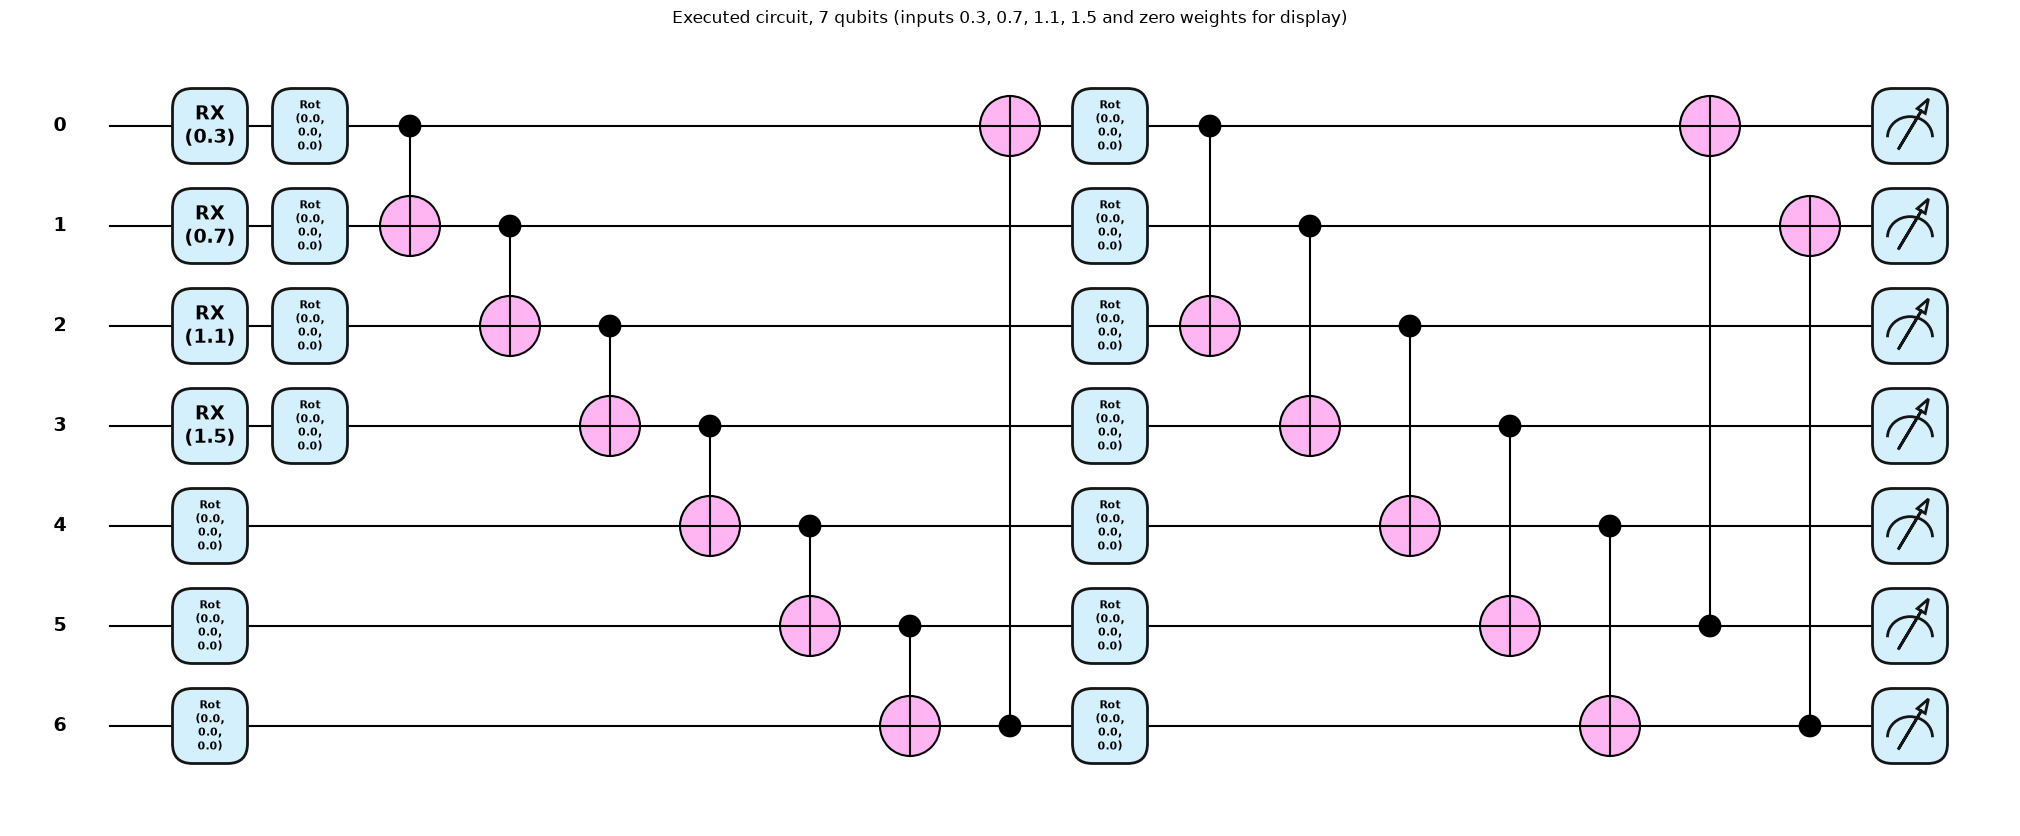

Matplotlib is building the font cache; this may take a moment.


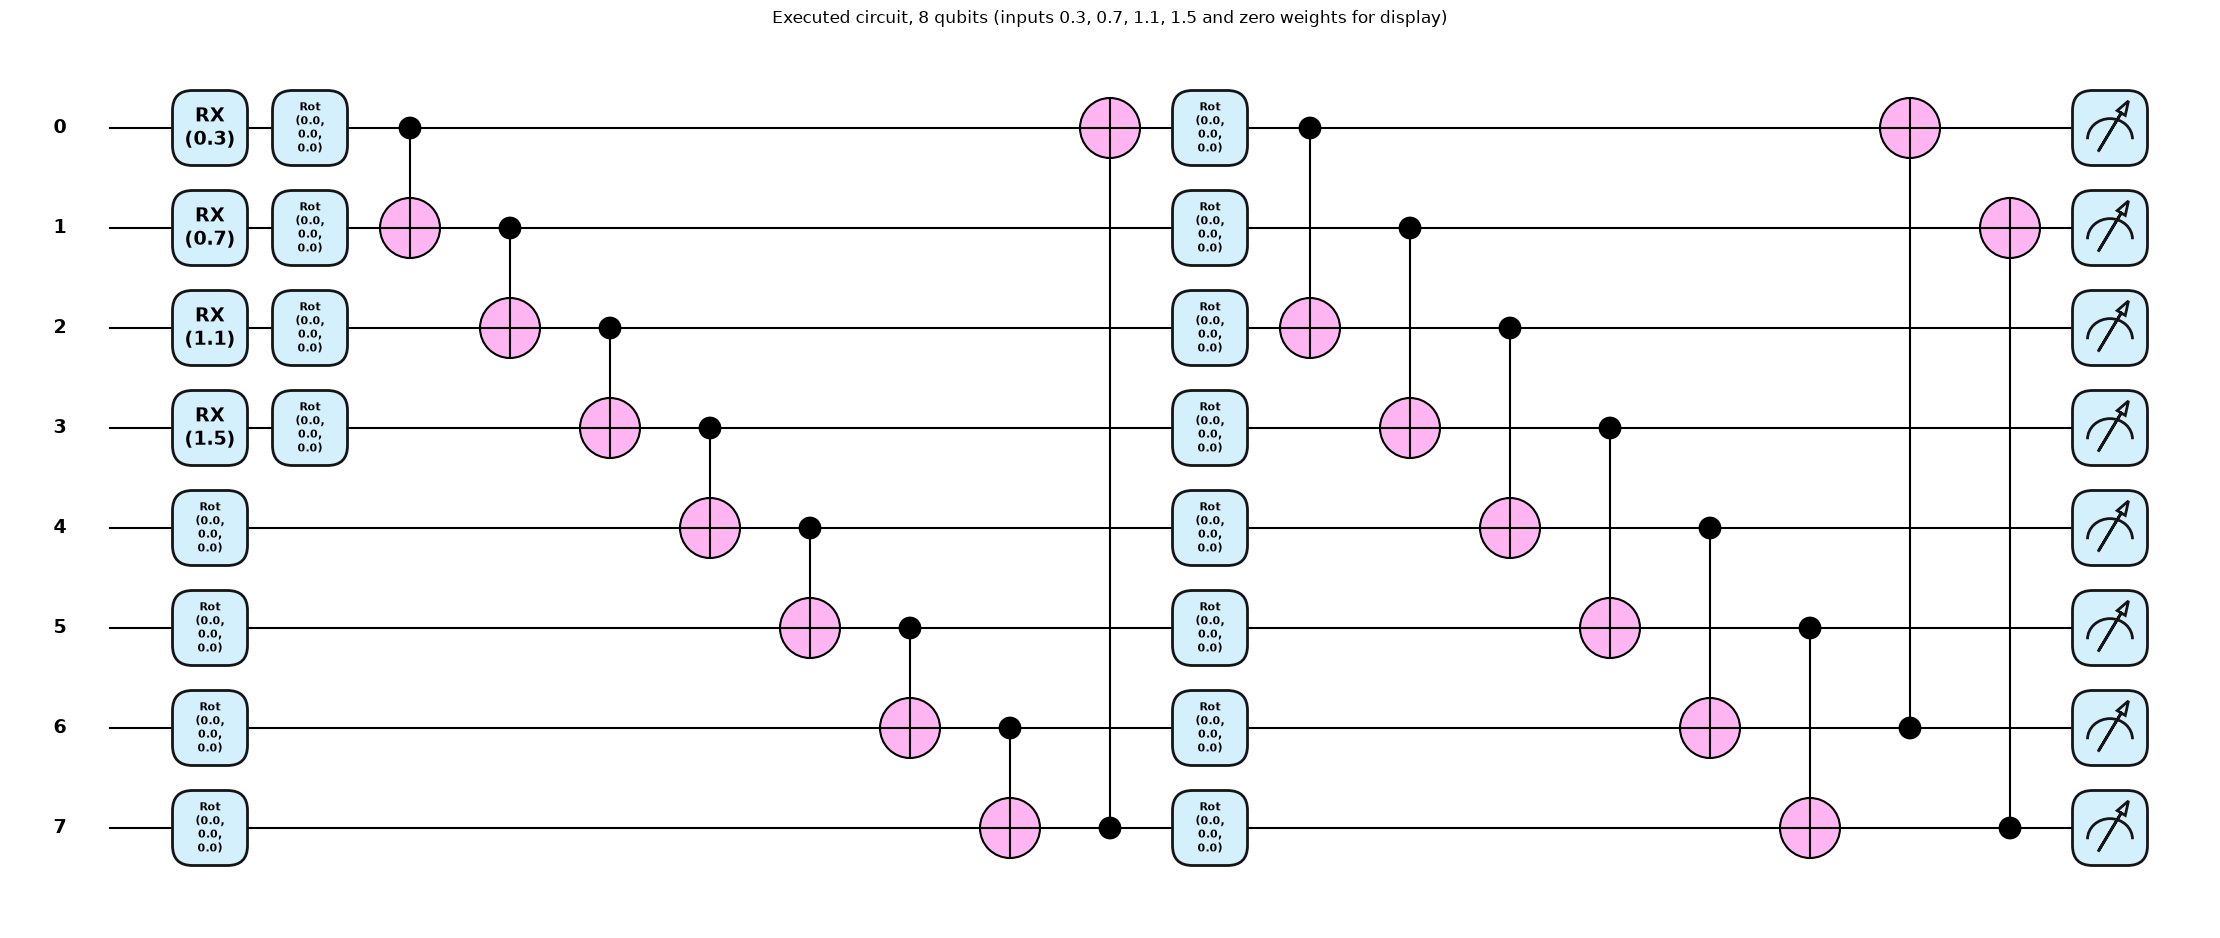

Matplotlib is building the font cache; this may take a moment.


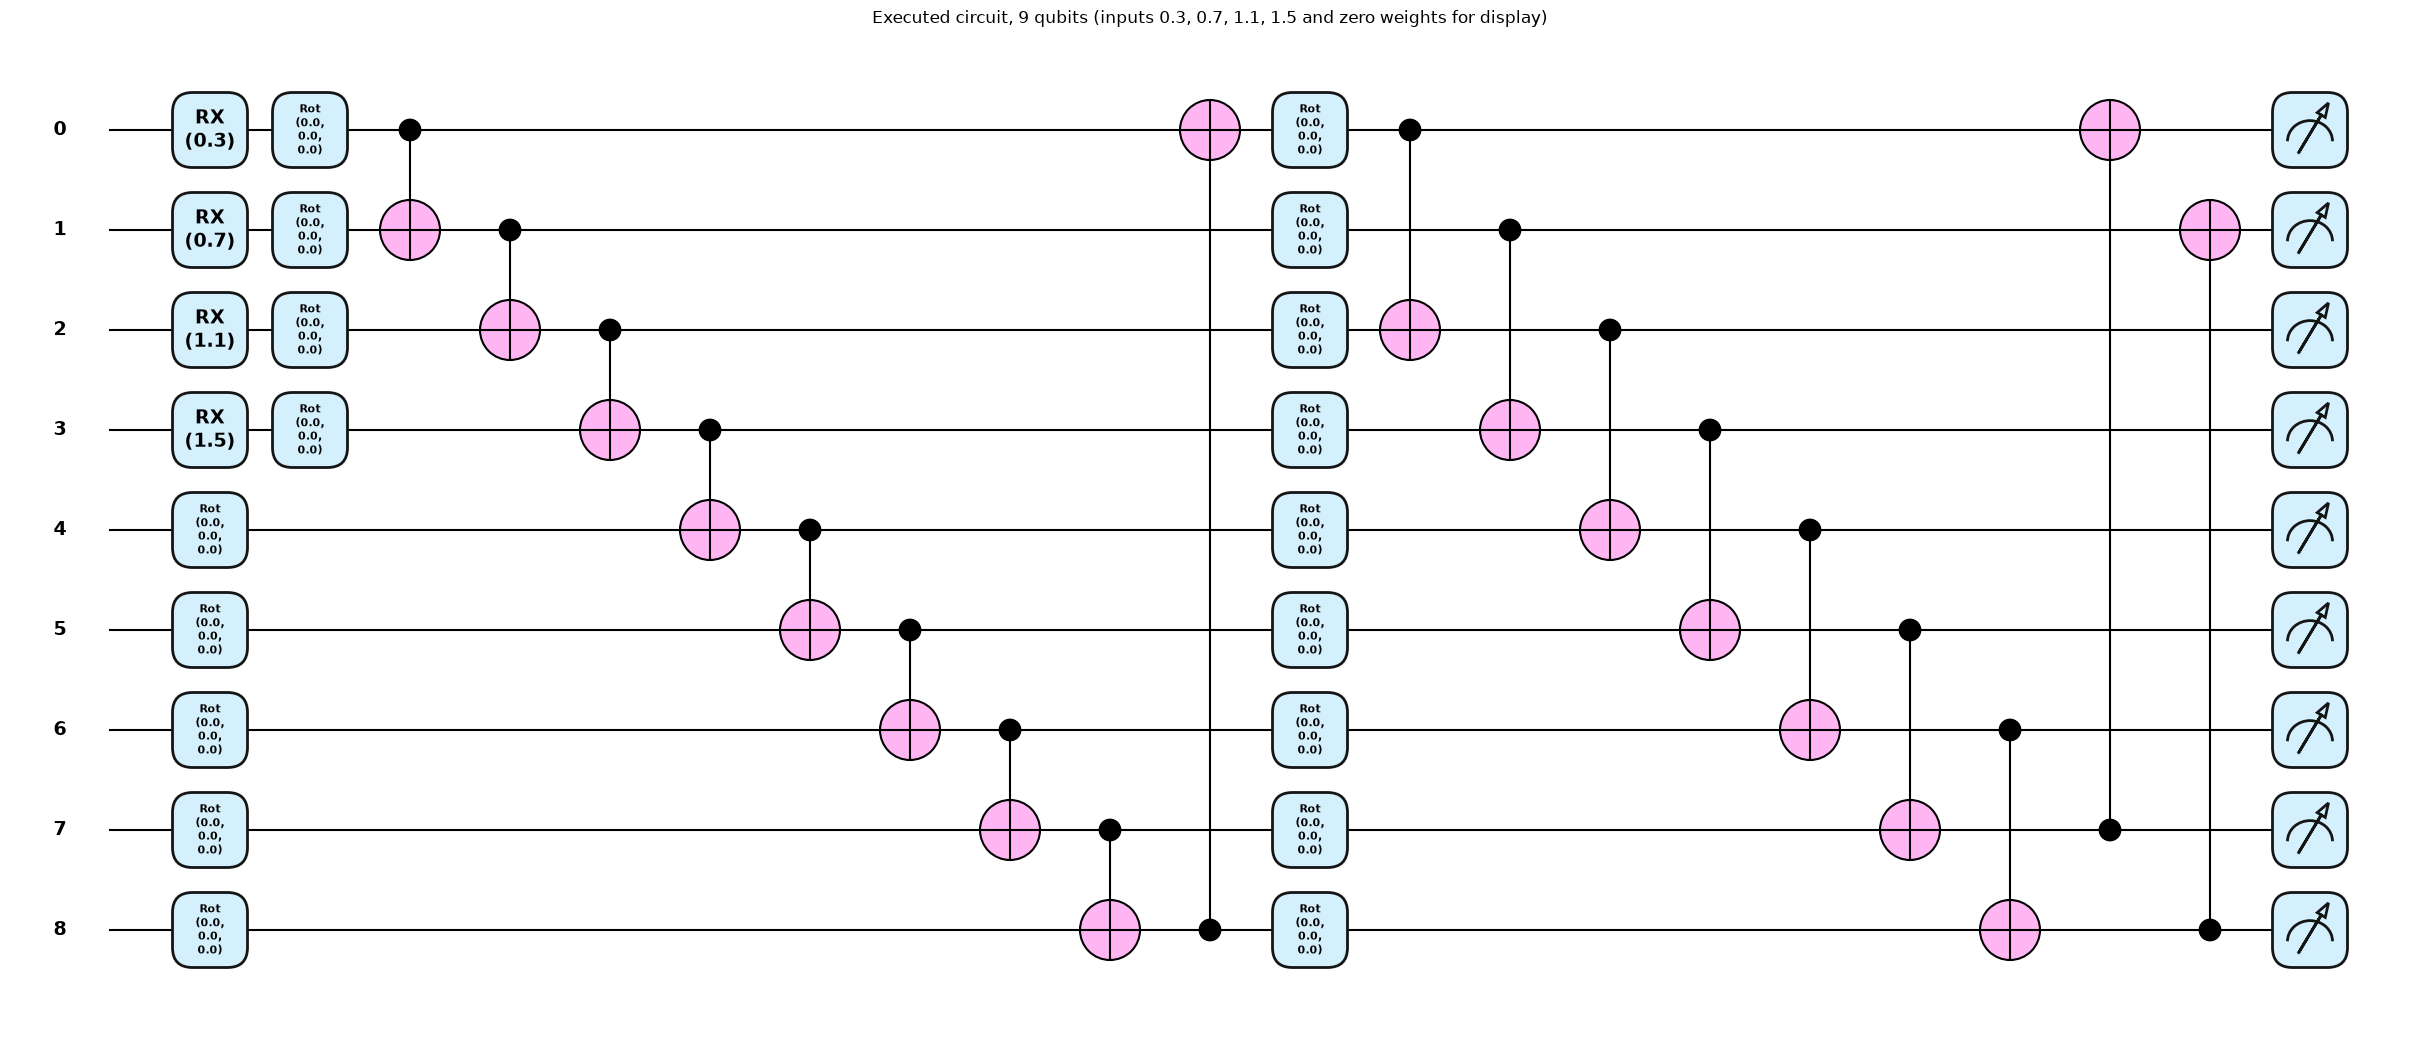

Matplotlib is building the font cache; this may take a moment.


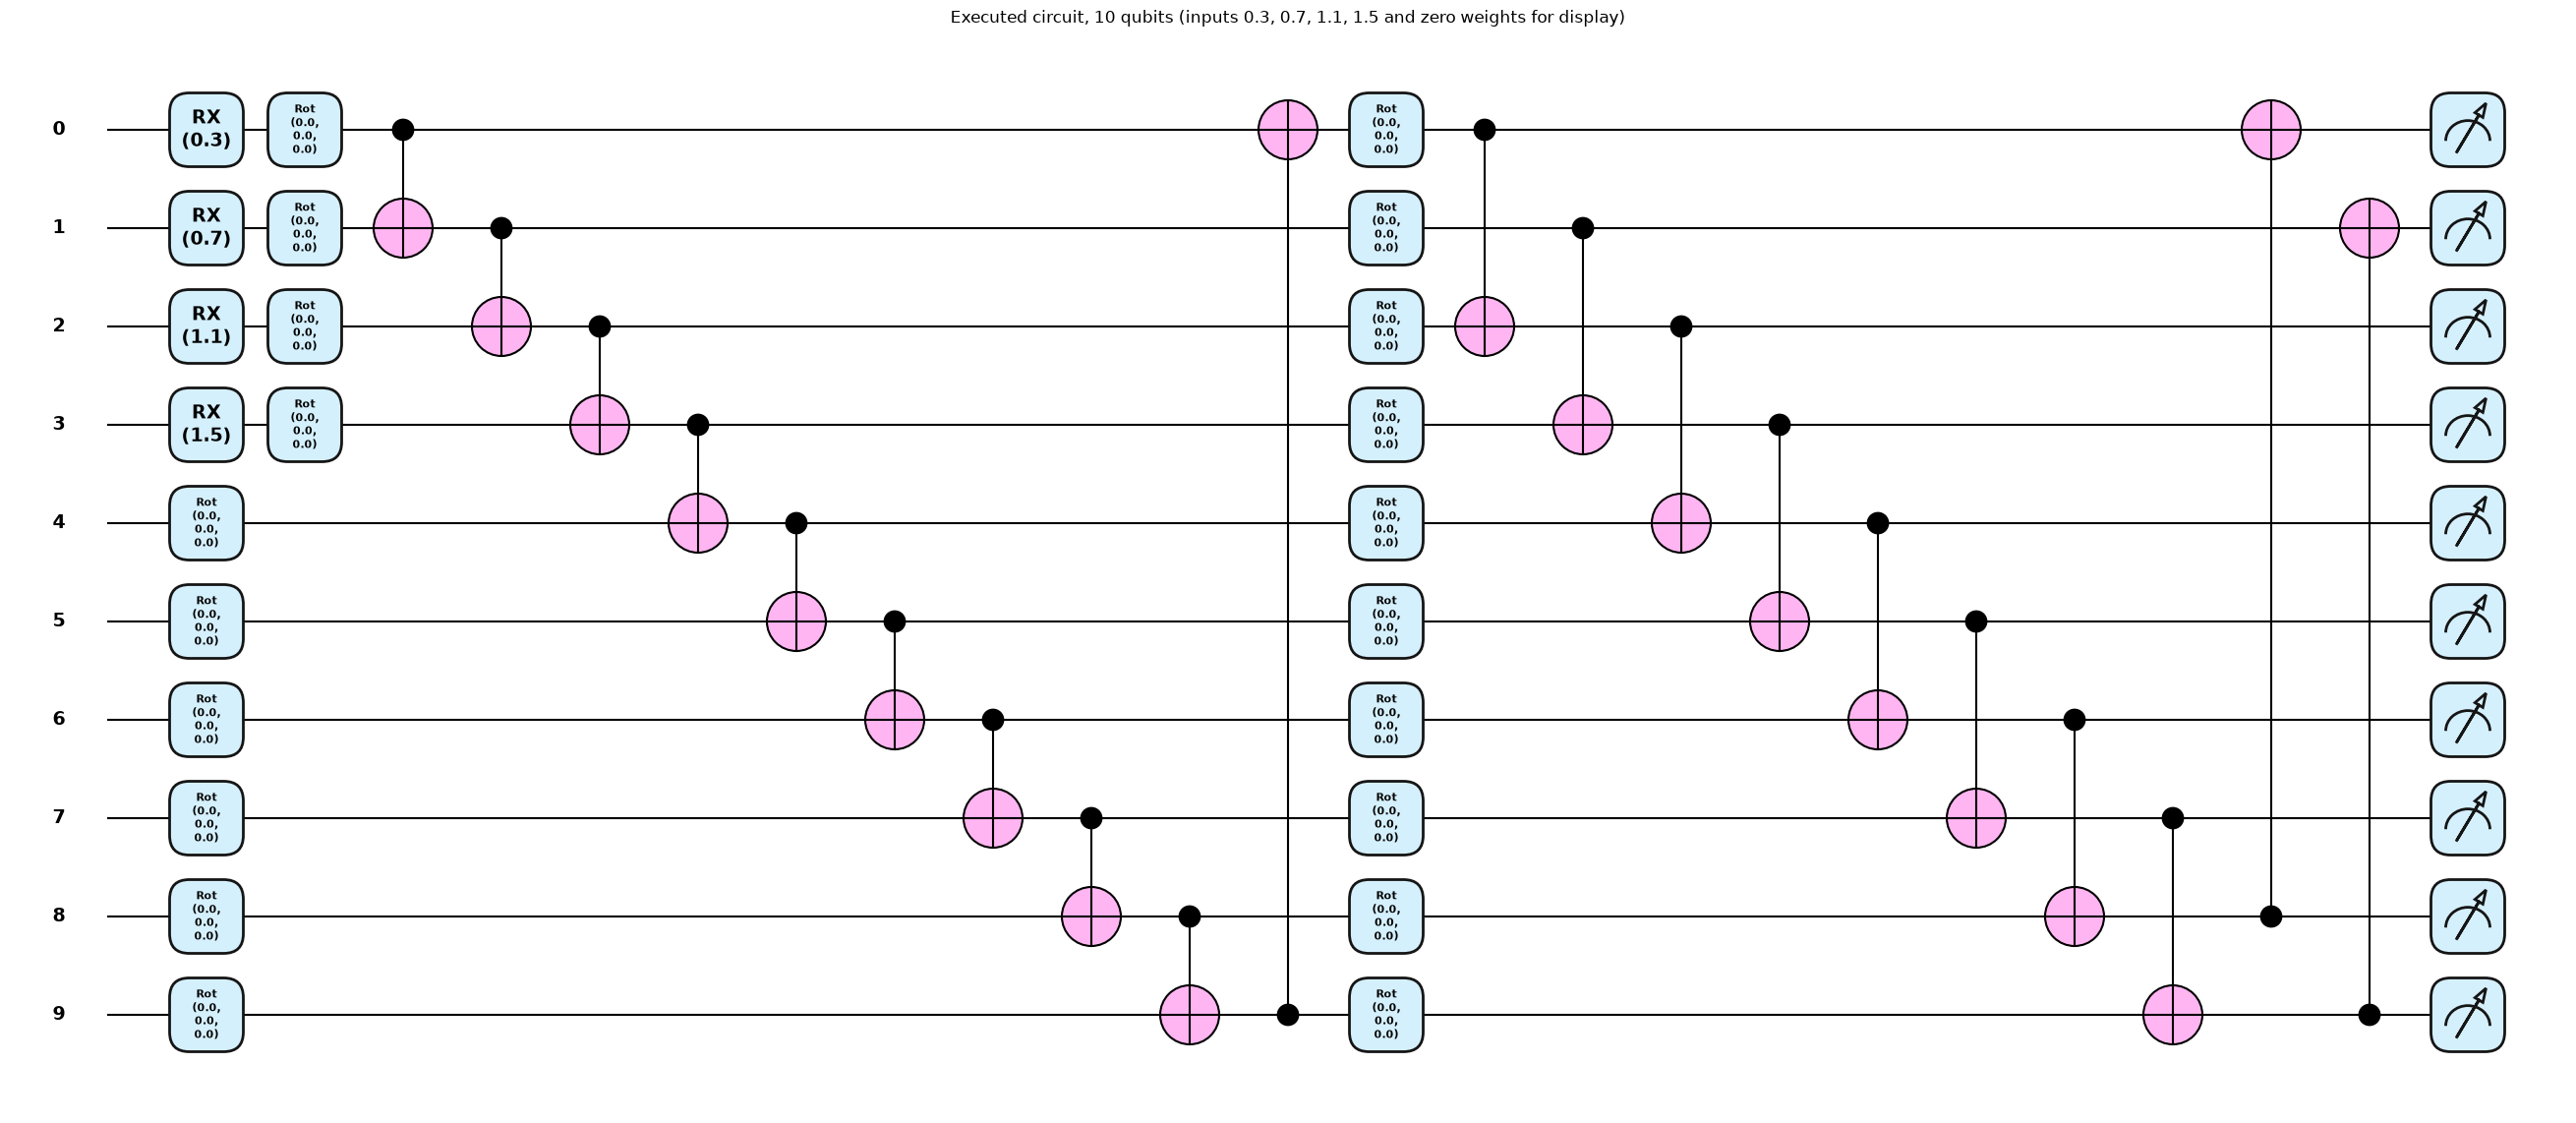

Matplotlib is building the font cache; this may take a moment.


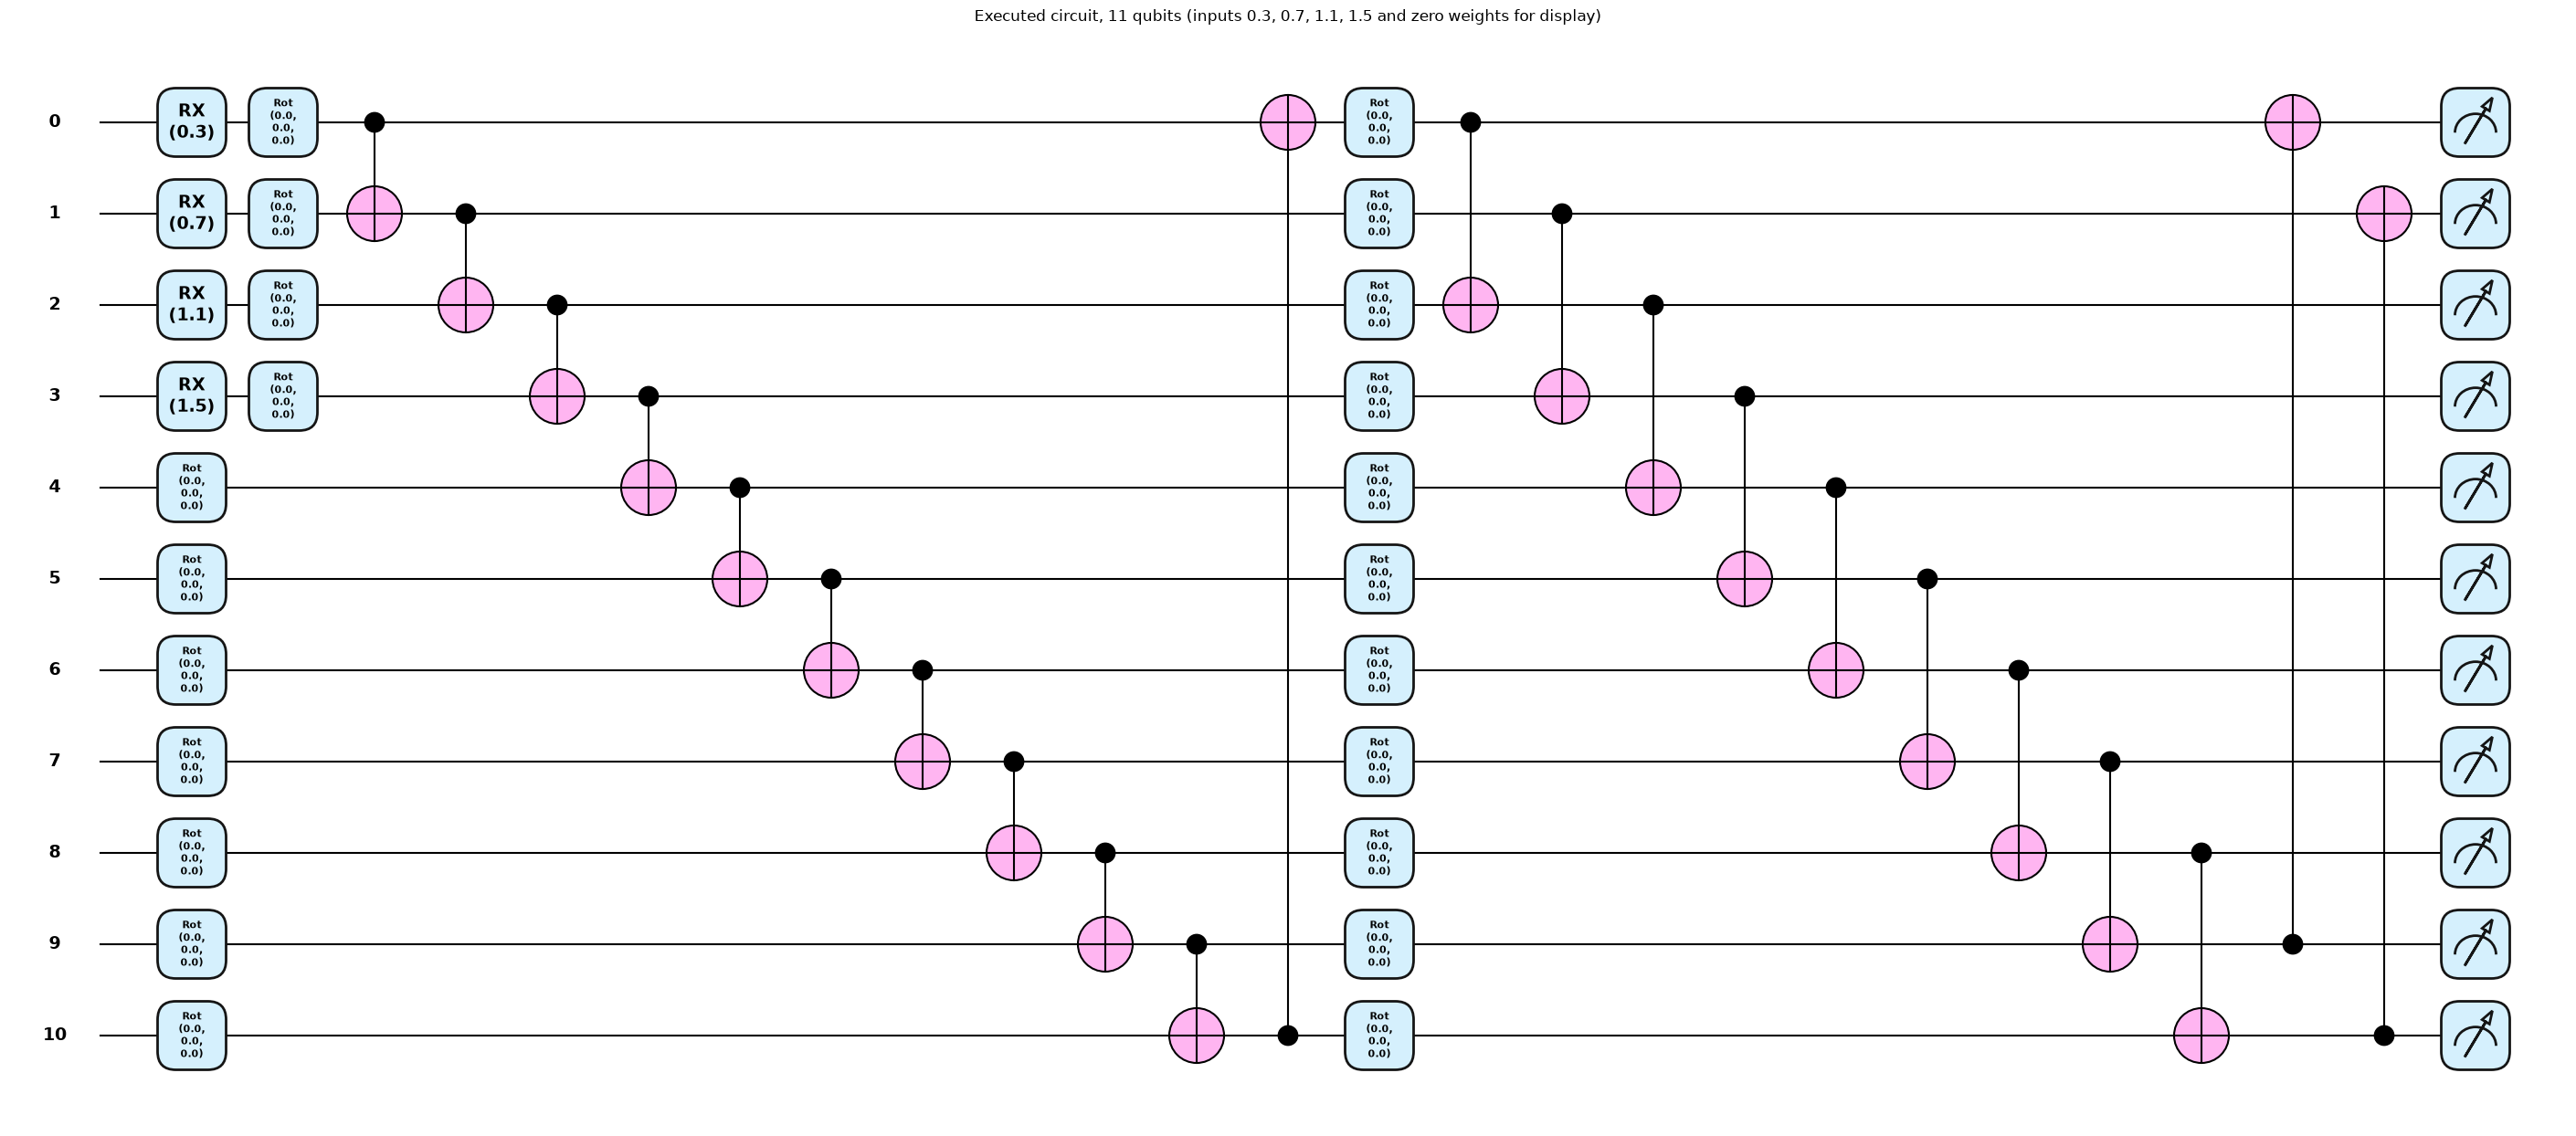

Matplotlib is building the font cache; this may take a moment.


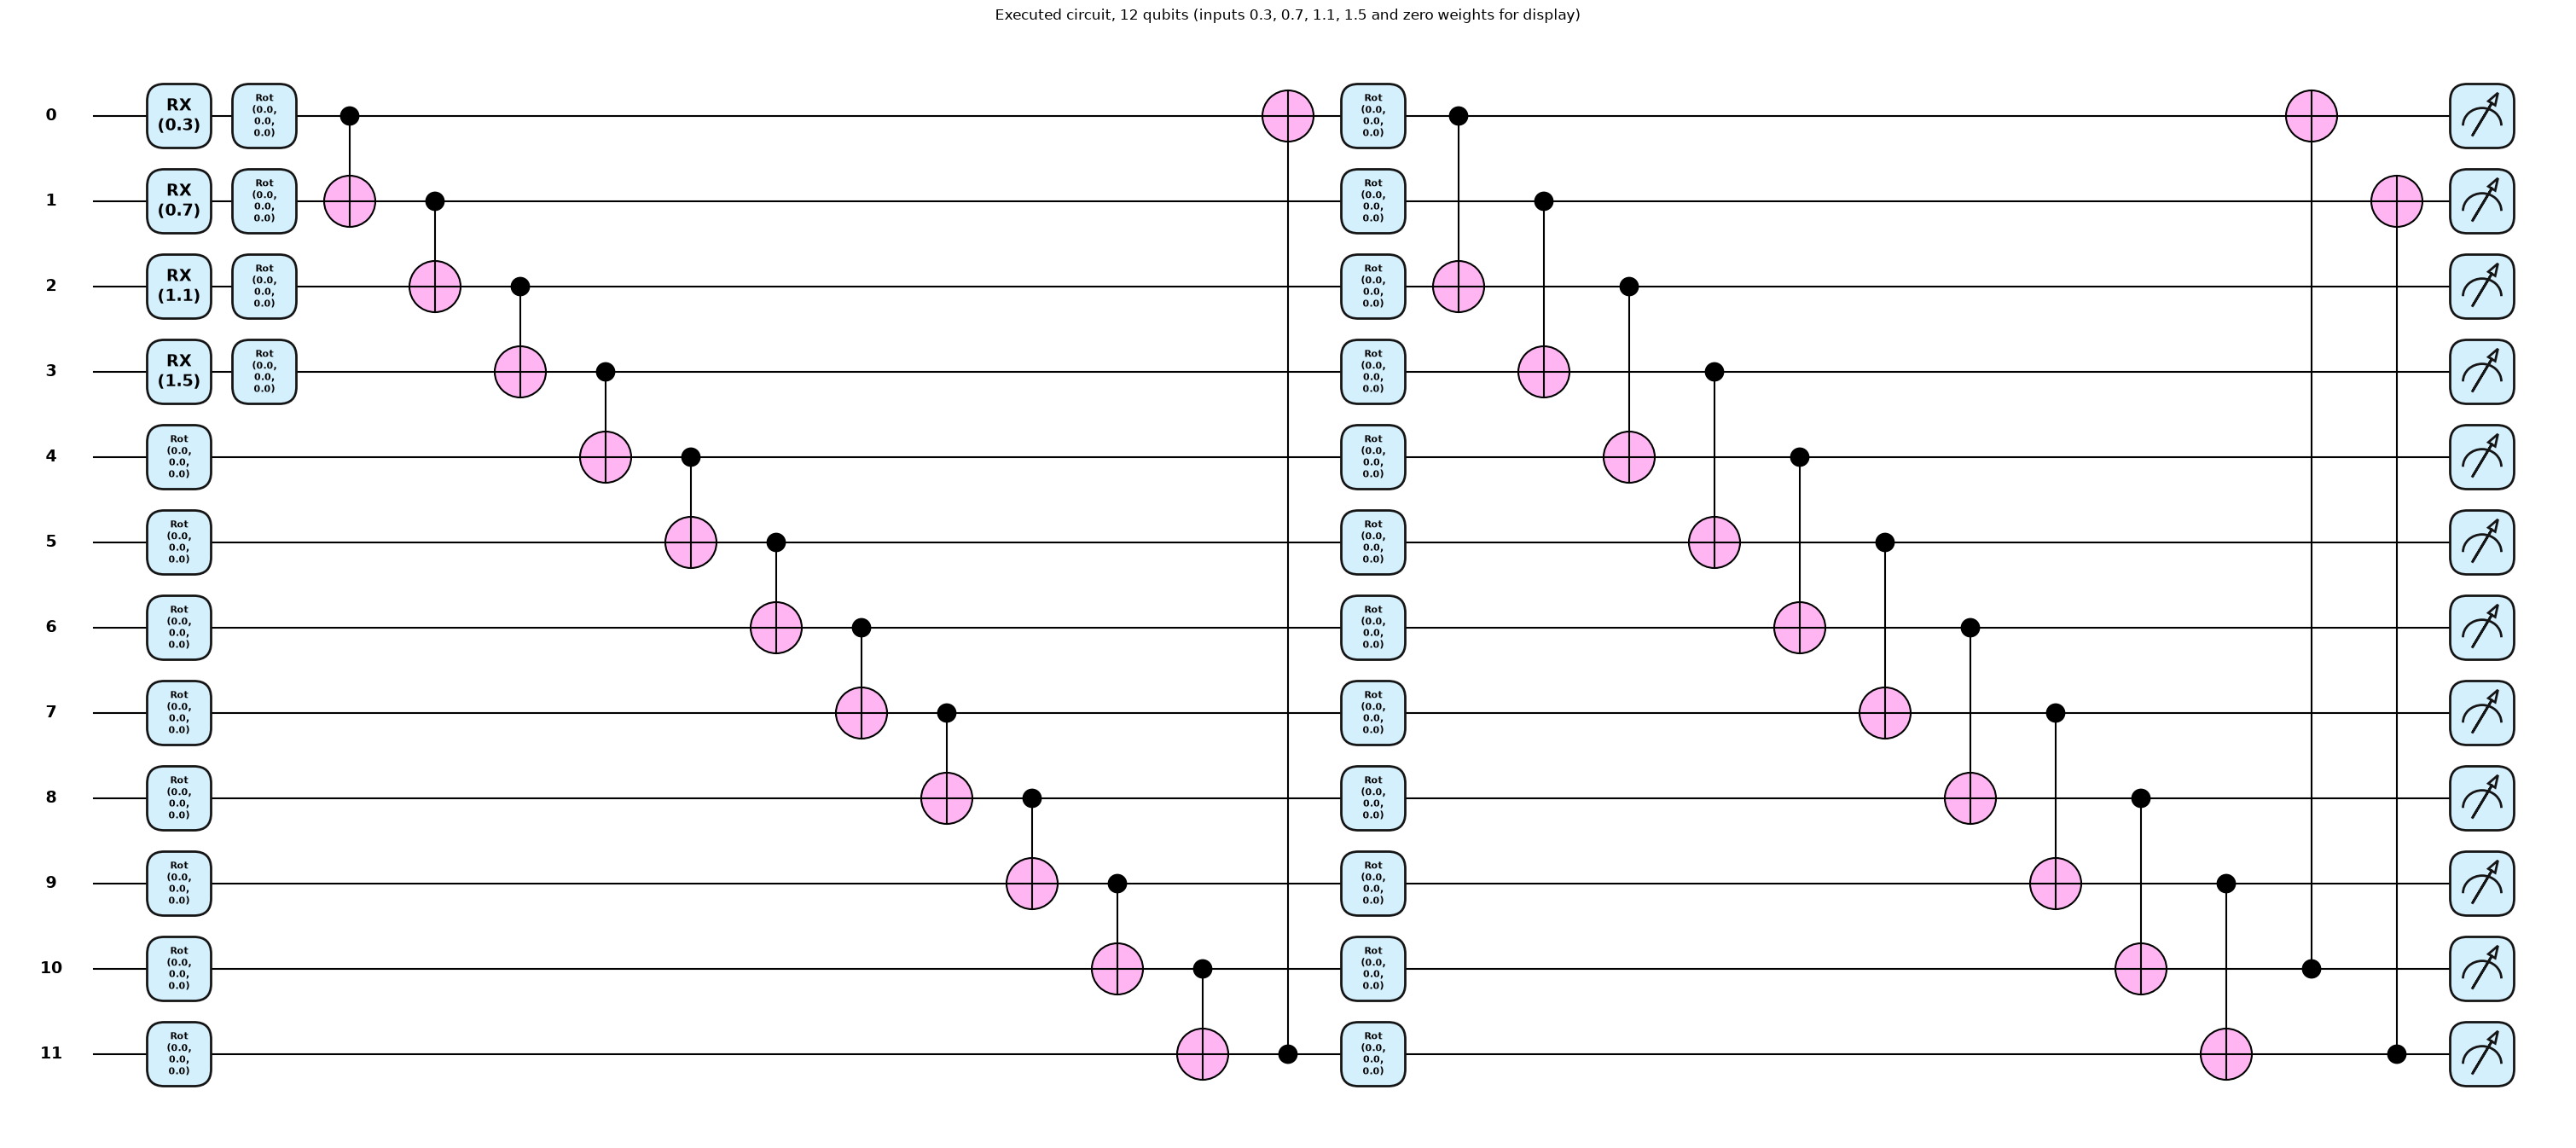

,qubits,depth,gates,quantum_params,total_trainable
0,4,9,20,24,49
1,5,11,24,30,56
2,6,12,28,36,63
3,7,14,32,42,70
4,8,15,36,48,77
5,9,17,40,54,84
6,10,18,44,60,91
7,11,20,48,66,98
8,12,21,52,72,105


In [10]:
def make_qnode(n, n_layers=N_LAYERS):
    dev = qml.device("default.qubit", wires=n)
    @qml.qnode(dev, interface="torch", diff_method="backprop")
    def circuit(inputs, weights):
        qml.AngleEmbedding(inputs, wires=range(N_FEATURES))                 # RX encoding of the 4 Dense outputs
        qml.StronglyEntanglingLayers(weights, wires=range(n))               # Rot + CNOT ring, n_layers times
        return [qml.expval(qml.PauliZ(i)) for i in range(n)]
    return circuit

arch_rows = []
for n in QUBITS:
    circ = make_qnode(n)
    x0 = torch.tensor([0.3, 0.7, 1.1, 1.5]); w0 = torch.zeros(N_LAYERS, n, 3)
    specs = qml.specs(circ, level="device")(x0, w0)
    res = specs["resources"]
    n_q = n * N_LAYERS * 3
    arch_rows.append(dict(qubits=n, depth=res.depth, gates=res.num_gates, quantum_params=n_q,
                          total_trainable=N_FEATURES*N_FEATURES + N_FEATURES + n_q + n + 1))
    fig, _ = qml.draw_mpl(circ, level="device", decimals=1, style="pennylane")(x0, w0)
    fig.suptitle(f"Executed circuit, {n} qubits (inputs 0.3, 0.7, 1.1, 1.5 and zero weights for display)", y=1.02)
    plt.show()
pd.DataFrame(arch_rows)


In [11]:
print("Qubit count, circuit depth (device level, after template expansion), trainable parameters per architecture:")
print(pd.DataFrame(arch_rows).to_string(index=False))
print("\nTrainable parameters = Linear(4,4): 20 + quantum weights N_LAYERS*n*3 + Linear(n,1): n+1")


Qubit count, circuit depth (device level, after template expansion), trainable parameters per architecture:
 qubits  depth  gates  quantum_params  total_trainable
      4      9     20              24               49
      5     11     24              30               56
      6     12     28              36               63
      7     14     32              42               70
      8     15     36              48               77
      9     17     40              54               84
     10     18     44              60               91
     11     20     48              66               98
     12     21     52              72              105

Trainable parameters = Linear(4,4): 20 + quantum weights N_LAYERS*n*3 + Linear(n,1): n+1


### A fast, exact twin of the PennyLane circuit

Simulating 12 qubits for thousands of samples through PennyLane's broadcasting is slow on a CPU (about 3 s per batch of 128). The circuit has a special structure: the embedding touches only wires 0-3, so the input state is a superposition of just **16 computational basis states**. We can therefore apply the (input-independent) variational block `V(weights)` to those 16 basis vectors once per batch, then combine them with the input-dependent amplitudes. The result is *mathematically identical* to the QNode (same gates, same `Rot` matrix, same CNOT ring, exact statevector), only much faster, and gradients come from torch autograd.

Because the claim "this is the circuit the paper describes" matters, the next cell **asserts** that the twin and the PennyLane `TorchLayer` agree on expectation values and on gradients for every qubit count used. Training uses the twin; after training, the trained weights are loaded into the PennyLane layer and the predictions are checked again.

In [12]:
torch.set_default_dtype(torch.float32)

class FastStronglyEntangling(nn.Module):
    """Exact statevector twin of AngleEmbedding(4 wires) + StronglyEntanglingLayers(n wires) + <Z_i> on all wires."""
    def __init__(self, n, n_layers):
        super().__init__()
        self.n, self.L = n, n_layers
        self.weights = nn.Parameter(torch.empty(n_layers, n, 3).uniform_(0, 2*np.pi))     # same init range as PennyLane's TorchLayer
        N = 2**n; idx = np.arange(N)
        bit = lambda w: (idx >> (n-1-w)) & 1                                              # wire 0 = most significant bit
        self.register_buffer("zsign", torch.tensor(np.stack([1 - 2*bit(w) for w in range(n)], 1), dtype=torch.float32))
        self.layer_perm = []
        for l in range(n_layers):
            r = (l % (n-1)) + 1                                                           # CNOT range of StronglyEntanglingLayers
            comp = np.arange(N)
            for i in range(n):
                c, t = i, (i + r) % n
                src = np.where(((idx >> (n-1-c)) & 1) == 1, idx ^ (1 << (n-1-t)), idx)   # CNOT(c, t) as an index permutation
                comp = comp[src]
            self.layer_perm.append(torch.tensor(comp, dtype=torch.long))
        k = np.arange(2**N_FEATURES)
        W0 = np.zeros((2**N_FEATURES, N)); W0[k, k << (n - N_FEATURES)] = 1                # |b0 b1 b2 b3 0...0>
        self.register_buffer("W0", torch.tensor(W0, dtype=torch.complex64))
        kb = np.stack([(k >> (N_FEATURES-1-j)) & 1 for j in range(N_FEATURES)], 1)
        self.register_buffer("kbits", torch.tensor(kb, dtype=torch.long))
    @staticmethod
    def rot(phi, theta, omega):                                                           # PennyLane Rot = RZ(omega) RY(theta) RZ(phi)
        c, s = torch.cos(theta/2), torch.sin(theta/2); a, b = (phi+omega)/2, (phi-omega)/2
        return torch.stack([torch.stack([torch.exp(-1j*a)*c, -torch.exp(1j*b)*s]),
                            torch.stack([torch.exp(-1j*b)*s,  torch.exp(1j*a)*c])])
    def apply_V(self):
        n, S = self.n, self.W0; K = S.shape[0]
        for l in range(self.L):
            for w in range(n):
                U = self.rot(*self.weights[l, w]); T = S.reshape(K, 2**w, 2, 2**(n-w-1))
                S = torch.stack([U[0, 0]*T[:, :, 0] + U[0, 1]*T[:, :, 1],
                                 U[1, 0]*T[:, :, 0] + U[1, 1]*T[:, :, 1]], dim=2).reshape(K, -1)
            S = S[:, self.layer_perm[l]]
        return S
    def forward(self, x):
        c, s = torch.cos(x/2).to(torch.complex64), torch.sin(x/2).to(torch.complex64)     # RX(x)|0> = (cos, -i sin)
        amp = torch.ones(x.shape[0], self.kbits.shape[0], dtype=torch.complex64)
        for j in range(N_FEATURES):
            amp = amp * torch.where(self.kbits[:, j][None, :] == 0, c[:, j:j+1], -1j*s[:, j:j+1])
        psi = amp @ self.apply_V()
        return (psi.real**2 + psi.imag**2) @ self.zsign

def pennylane_layer(n):
    return qml.qnn.TorchLayer(make_qnode(n), {"weights": (N_LAYERS, n, 3)})

# Equivalence test: expectation values and gradients, every qubit count
torch.manual_seed(SEED)
for n in QUBITS:
    fast, ref = FastStronglyEntangling(n, N_LAYERS), pennylane_layer(n)
    with torch.no_grad(): ref.weights.copy_(fast.weights)
    xb = (torch.rand(48, 4) * np.pi).requires_grad_(True)
    a, b = fast(xb), ref(xb)
    ga = torch.autograd.grad(a.sum(), fast.weights)[0]; gb = torch.autograd.grad(b.sum(), ref.weights)[0]
    d_out, d_grad = (a - b).abs().max().item(), (ga - gb).abs().max().item()
    assert d_out < 1e-4 and d_grad < 1e-3, (n, d_out, d_grad)
    print(f"n={n:2d}  max |<Z> difference| = {d_out:.1e}   max |gradient difference| = {d_grad:.1e}   OK")


n= 4  max |<Z> difference| = 2.4e-07   max |gradient difference| = 2.9e-06   OK


n= 5  max |<Z> difference| = 1.6e-07   max |gradient difference| = 2.1e-06   OK


n= 6  max |<Z> difference| = 1.8e-07   max |gradient difference| = 4.3e-06   OK


n= 7  max |<Z> difference| = 2.2e-07   max |gradient difference| = 2.0e-06   OK


n= 8  max |<Z> difference| = 3.1e-07   max |gradient difference| = 6.7e-06   OK


n= 9  max |<Z> difference| = 2.7e-07   max |gradient difference| = 1.7e-06   OK


n=10  max |<Z> difference| = 3.2e-07   max |gradient difference| = 1.4e-06   OK


n=11  max |<Z> difference| = 1.2e-07   max |gradient difference| = 1.3e-06   OK


n=12  max |<Z> difference| = 1.5e-07   max |gradient difference| = 1.6e-06   OK


## 3. Classical baselines on exactly the same inputs

The paper states that the quantum model reached accuracy "comparable to the classical methods" but gives no numbers. We train, on the same four MinMax-scaled attributes and the same split: logistic regression, an RBF-kernel SVC and a RandomForest; and, as additional context, RF and SVC on all 55 features. Metrics use the same macro averaging as the paper's Table II.

In [13]:
def metrics(y_true, y_pred):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    pb, rb, fb, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1, zero_division=0)
    return dict(accuracy=accuracy_score(y_true, y_pred), precision=p, recall=r, f1=f,
                precision_mal=pb, recall_mal=rb, f1_mal=fb)

baseline_rows, baseline_preds = [], {}
def run_baseline(name, model, Xa, Xb, ya, yb):
    t = time.time(); model.fit(Xa, ya); yp = model.predict(Xb); dt = time.time() - t
    baseline_preds[name] = yp
    baseline_rows.append(dict(model=name, **metrics(yb, yp), seconds=dt))

run_baseline("LogReg (4 attrs)", LogisticRegression(max_iter=1000, random_state=SEED), np.vstack([X_tr, X_val]), X_te, np.r_[y_tr, y_val], y_te)
run_baseline("SVC rbf (4 attrs)", SVC(kernel="rbf", C=1.0, random_state=SEED), np.vstack([X_tr, X_val]), X_te, np.r_[y_tr, y_val], y_te)
run_baseline("RandomForest (4 attrs)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2), np.vstack([X_tr, X_val]), X_te, np.r_[y_tr, y_val], y_te)

# All 55 features (context only), scaler fitted on the training split
sc55 = MinMaxScaler().fit(sample.loc[idx_tr_all, feature_cols_all].values)
X55_tr = sc55.transform(sample.loc[idx_tr_all, feature_cols_all].values)
X55_te = np.clip(sc55.transform(sample.loc[idx_te, feature_cols_all].values), 0, 1)
run_baseline("SVC rbf (all 55 features)", SVC(kernel="rbf", C=1.0, random_state=SEED), X55_tr, X55_te, y_all[idx_tr_all], y_te)
run_baseline("RandomForest (all 55 features)", RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=2), X55_tr, X55_te, y_all[idx_tr_all], y_te)
baseline_df = pd.DataFrame(baseline_rows).set_index("model")
baseline_df.round(4)


,accuracy,precision,recall,f1,precision_mal,recall_mal,f1_mal,seconds
model,,,,,,,,
LogReg (4 attrs),0.9850,0.9851,0.9850,0.9850,0.9778,0.9925,0.9851,0.3553
SVC rbf (4 attrs),0.9956,0.9956,0.9956,0.9956,0.9975,0.9938,0.9956,0.8070
RandomForest (4 attrs),0.9981,0.9981,0.9981,0.9981,0.9987,0.9975,0.9981,6.0339
SVC rbf (all 55 features),0.9969,0.9969,0.9969,0.9969,0.9963,0.9975,0.9969,2.8389
RandomForest (all 55 features),1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,7.1106


## 4. Training the hybrid quantum network

Architecture per qubit count `n` (paper Fig. 6 and its Keras summary): `Linear(4, 4)` (linear, as a default Keras `Dense`) -> quantum layer with `n` outputs -> `Linear(n, 1)` -> sigmoid. Loss: binary cross-entropy; optimiser Adam. The weights of the quantum layer start uniformly in [0, 2 pi] (PennyLane's default).

A **classical twin** is trained with the same seeds and schedule: the quantum layer is replaced by `Linear(4, n)` + `tanh`. This separates "what the quantum layer adds" from "what a tiny network does anyway", and gives the training-time comparison the paper mentions only qualitatively.

In [14]:
class HybridNet(nn.Module):
    def __init__(self, n, quantum=True, qlayer=None):
        super().__init__()
        self.pre = nn.Linear(N_FEATURES, N_FEATURES)
        if quantum:
            self.mid = qlayer if qlayer is not None else FastStronglyEntangling(n, N_LAYERS)
        else:
            self.mid = nn.Sequential(nn.Linear(N_FEATURES, n), nn.Tanh())
        self.post = nn.Linear(n, 1)
    def forward(self, x):
        return self.post(self.mid(self.pre(x))).squeeze(-1)

def to_t(a): return torch.tensor(a, dtype=torch.float32)
Xt_tr, Xt_val, Xt_te = to_t(X_tr), to_t(X_val), to_t(X_te)
yt_tr, yt_val = to_t(y_tr), to_t(y_val)
lossf = nn.BCEWithLogitsLoss()

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        z = model(X); loss = lossf(z, y).item(); pred = (z > 0).float()
    model.train()
    return loss, (pred == y).float().mean().item(), pred.numpy().astype(int)

def train_model(n, seed, quantum=True):
    seed_everything(seed)
    model = HybridNet(n, quantum=quantum)
    opt = torch.optim.Adam(model.parameters(), lr=LR)
    g = torch.Generator().manual_seed(seed)
    hist = dict(loss=[], acc=[], val_loss=[], val_acc=[])
    t0 = time.time()
    for ep in range(EPOCHS):
        perm = torch.randperm(len(Xt_tr), generator=g); tl, ta, nb = 0.0, 0.0, 0
        for i in range(0, len(Xt_tr), BATCH_SIZE):
            b = perm[i:i+BATCH_SIZE]
            opt.zero_grad(); z = model(Xt_tr[b]); l = lossf(z, yt_tr[b]); l.backward(); opt.step()
            tl += l.item() * len(b); ta += ((z.detach() > 0).float() == yt_tr[b]).float().sum().item(); nb += len(b)
        vl, va, _ = evaluate(model, Xt_val, yt_val)
        hist["loss"].append(tl/nb); hist["acc"].append(ta/nb); hist["val_loss"].append(vl); hist["val_acc"].append(va)
    train_time = time.time() - t0
    t1 = time.time(); _, _, pred = evaluate(model, Xt_te, to_t(y_te)); pred_time = time.time() - t1
    return model, hist, pred, train_time, pred_time

import pickle, gc
# Runs are cached on disk (DATA_DIR) so an interrupted session (Colab disconnect, out-of-memory) resumes where it stopped.
CACHE_KEY = dict(N_TOTAL=N_TOTAL, EPOCHS=EPOCHS, LR=LR, BATCH_SIZE=BATCH_SIZE, N_LAYERS=N_LAYERS, SEED=SEED)
CACHE_FILE = os.path.join(DATA_DIR, "runs_cache_%s.pkl" % ("fast" if FAST_MODE else "full"))
cache = {}
if os.path.exists(CACHE_FILE):
    try:
        with open(CACHE_FILE, "rb") as fh: blob = pickle.load(fh)
        if blob.get("key") == CACHE_KEY:
            cache = blob["runs"]; print("resuming: %d finished runs found in %s" % (len(cache), CACHE_FILE))
    except Exception as e:
        print("cache ignored:", type(e).__name__)
def save_cache():
    with open(CACHE_FILE, "wb") as fh: pickle.dump(dict(key=CACHE_KEY, runs=cache), fh)

results = []        # one row per (kind, qubits, seed)
histories, preds, saved_models = {}, {}, {}
for kind in ["quantum", "classical twin"]:
    for n in QUBITS:
        for s in SEEDS_BY_QUBIT[n]:
            key = (kind, n, s)
            if key not in cache:
                for attempt in range(4):                       # retry on transient out-of-memory errors
                    try:
                        model, hist, pred, tt, pt = train_model(n, s, quantum=(kind == "quantum")); break
                    except RuntimeError as e:
                        print("  retry after", str(e)[:60]); gc.collect(); time.sleep(30)
                else:
                    raise RuntimeError("training failed repeatedly for %s" % (key,))
                cache[key] = dict(hist=hist, pred=pred, tt=tt, pt=pt,
                                  state=(model.state_dict() if (kind == "quantum" and s == SEEDS[0]) else None))
                save_cache(); model = None; gc.collect()
            r = cache[key]; m = metrics(y_te, r["pred"])
            results.append(dict(kind=kind, qubits=n, seed=s, **m, train_s=r["tt"], predict_s=r["pt"], final_val_acc=r["hist"]["val_acc"][-1]))
            histories[key] = r["hist"]; preds[key] = r["pred"]
            if r["state"] is not None:
                mdl = HybridNet(n, quantum=True); mdl.load_state_dict(r["state"]); saved_models[n] = mdl
            print(f"{kind:14s} n={n:2d} seed={s}  test acc={m['accuracy']:.4f}  macroF1={m['f1']:.4f}  train {r['tt']:6.1f}s")
res = pd.DataFrame(results)


quantum        n= 4 seed=42  test acc=0.9781  macroF1=0.9781  train   20.6s


quantum        n= 5 seed=42  test acc=0.9788  macroF1=0.9787  train   22.1s


quantum        n= 6 seed=42  test acc=0.9788  macroF1=0.9787  train   22.2s


quantum        n= 7 seed=42  test acc=0.9781  macroF1=0.9781  train   28.2s


quantum        n= 8 seed=42  test acc=0.9806  macroF1=0.9806  train   50.5s


...

classical twin n= 8 seed=42  test acc=0.9831  macroF1=0.9831  train    1.5s


classical twin n= 9 seed=42  test acc=0.9831  macroF1=0.9831  train    1.3s


classical twin n=10 seed=42  test acc=0.9831  macroF1=0.9831  train    1.4s


classical twin n=11 seed=42  test acc=0.9831  macroF1=0.9831  train    1.3s


classical twin n=12 seed=42  test acc=0.9825  macroF1=0.9825  train    2.2s


## 5. Results: the analogue of Table II and Fig. 7

Precision, recall and F1 are **macro-averaged** over the two classes, as in the paper (the paper's collapse rows can only be reproduced with macro averaging). Values are mean +/- std over seeds; the per-class metrics with malware as the positive class are in the last table.

In [15]:
def ms(series):
    return f"{series.mean():.3f}" if len(series) == 1 else f"{series.mean():.3f} +/- {series.std(ddof=0):.3f}"
q = res[res.kind == "quantum"]; c = res[res.kind == "classical twin"]
table2 = q.groupby("qubits").agg(Precision=("precision", ms), Recall=("recall", ms), F1=("f1", ms), Accuracy=("accuracy", ms),
                                 train_s=("train_s", lambda s: f"{s.mean():.1f}"))
print("Hybrid QNN (this notebook), test split:"); print(table2.to_string())
print("\nClassical twin (quantum layer -> Linear+tanh), test split:")
print(c.groupby("qubits").agg(Precision=("precision", ms), Recall=("recall", ms), F1=("f1", ms), Accuracy=("accuracy", ms),
                              train_s=("train_s", lambda s: f"{s.mean():.1f}")).to_string())
print("\nMalware as the positive class (attack = positive), hybrid QNN:")
print(q.groupby("qubits").agg(P_mal=("precision_mal", ms), R_mal=("recall_mal", ms), F1_mal=("f1_mal", ms)).to_string())
print("\nSeeds that collapsed to (almost) one class (test accuracy < 0.7):")
print(res[res.accuracy < 0.7][["kind", "qubits", "seed", "accuracy"]].to_string(index=False) if (res.accuracy < 0.7).any() else "none")


Hybrid QNN (this notebook), test split:
       Precision Recall     F1 Accuracy train_s
qubits                                         
4          0.978  0.978  0.978    0.978    20.6
5          0.979  0.979  0.979    0.979    22.1
6          0.979  0.979  0.979    0.979    22.2
7          0.978  0.978  0.978    0.978    28.2
8          0.981  0.981  0.981    0.981    50.5
9          0.981  0.981  0.981    0.981    43.4
10         0.980  0.980  0.980    0.980    33.5
11         0.981  0.981  0.981    0.981    39.8
12         0.980  0.979  0.979    0.979   146.6

Classical twin (quantum layer -> Linear+tanh), test split:
       Precision Recall     F1 Accuracy train_s
qubits                                         
4          0.983  0.983  0.983    0.983     1.5
5          0.983  0.983  0.982    0.983     1.2
6          0.983  0.983  0.983    0.983     1.4
7          0.983  0.983  0.983    0.983     2.6
8          0.983  0.983  0.983    0.983     1.5
9          0.983  0.983  0.983    0.

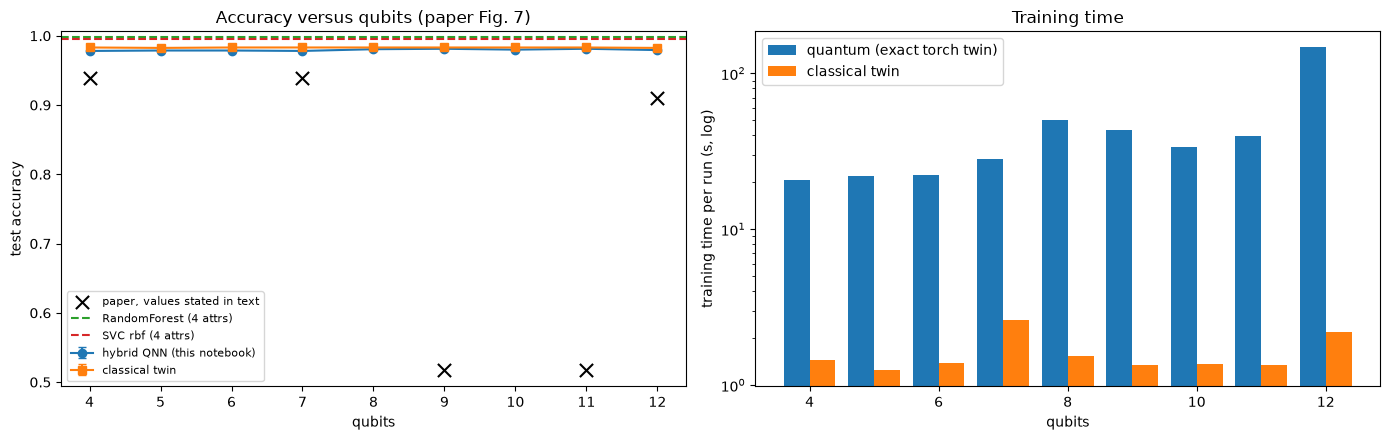

In [16]:
# Fig. 7 analogue: test accuracy versus number of qubits, with baselines
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
g = q.groupby("qubits").accuracy; gc = c.groupby("qubits").accuracy
ax[0].errorbar(g.mean().index, g.mean(), yerr=g.std(ddof=0), marker="o", capsize=3, label="hybrid QNN (this notebook)")
ax[0].errorbar(gc.mean().index, gc.mean(), yerr=gc.std(ddof=0), marker="s", capsize=3, label="classical twin")
paper_acc = {4: .939, 7: .939, 9: .517, 11: .517, 12: .91}
ax[0].scatter(list(paper_acc), list(paper_acc.values()), marker="x", s=90, color="k", label="paper, values stated in text", zorder=5)
for name, col in [("RandomForest (4 attrs)", "tab:green"), ("SVC rbf (4 attrs)", "tab:red")]:
    ax[0].axhline(baseline_df.loc[name, "accuracy"], ls="--", color=col, label=name)
ax[0].set_xlabel("qubits"); ax[0].set_ylabel("test accuracy"); ax[0].set_title("Accuracy versus qubits (paper Fig. 7)"); ax[0].legend(fontsize=8)
ax[1].bar(q.groupby("qubits").train_s.mean().index - 0.2, q.groupby("qubits").train_s.mean(), width=0.4, label="quantum (exact torch twin)")
ax[1].bar(c.groupby("qubits").train_s.mean().index + 0.2, c.groupby("qubits").train_s.mean(), width=0.4, label="classical twin")
ax[1].set_yscale("log"); ax[1].set_xlabel("qubits"); ax[1].set_ylabel("training time per run (s, log)"); ax[1].legend(); ax[1].set_title("Training time")
plt.tight_layout(); plt.show()


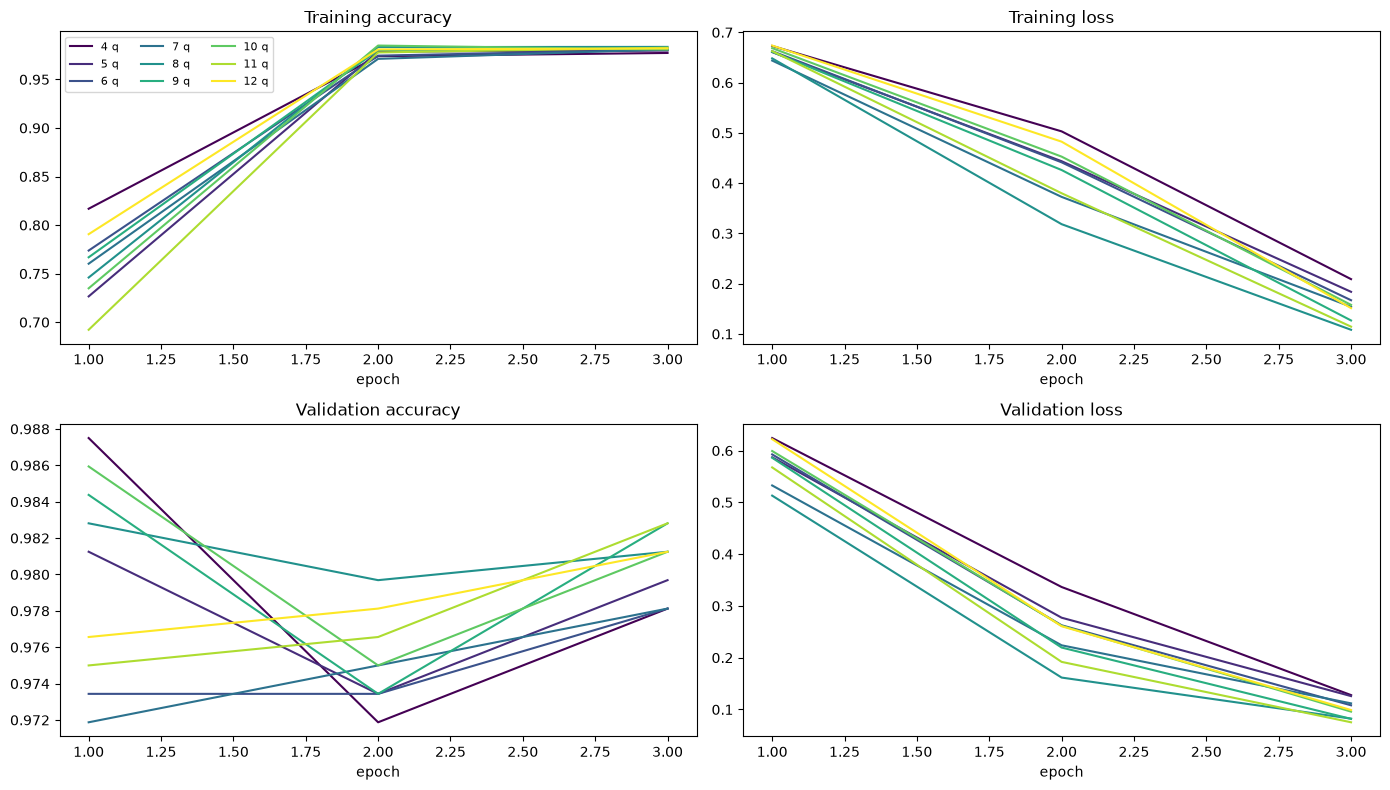

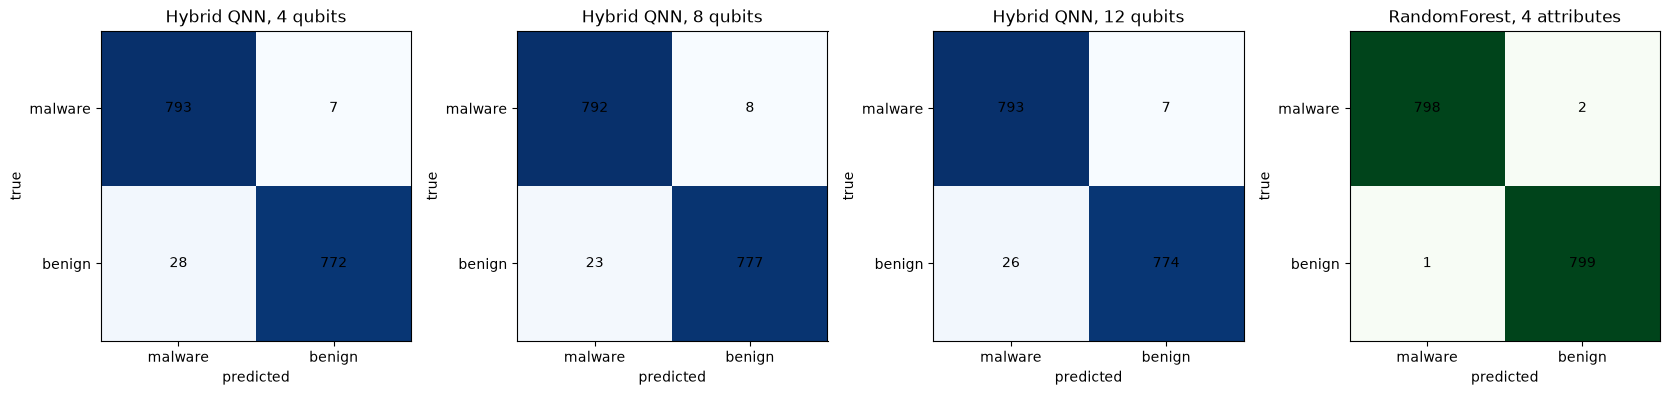

In [17]:
# Figs. 8-13 analogue: training and validation accuracy / loss versus epoch, seed = first seed
fig, ax = plt.subplots(2, 2, figsize=(14, 8)); cmap = plt.cm.viridis(np.linspace(0, 1, len(QUBITS)))
for col, n in zip(cmap, QUBITS):
    h = histories[("quantum", n, SEEDS[0])]; e = np.arange(1, EPOCHS+1)
    ax[0, 0].plot(e, h["acc"], color=col, label=f"{n} q"); ax[0, 1].plot(e, h["loss"], color=col)
    ax[1, 0].plot(e, h["val_acc"], color=col); ax[1, 1].plot(e, h["val_loss"], color=col)
for a, t in zip(ax.ravel(), ["Training accuracy", "Training loss", "Validation accuracy", "Validation loss"]):
    a.set_title(t); a.set_xlabel("epoch")
ax[0, 0].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()

# Confusion matrices (malware = positive class) for 4, 8 and 12 qubits, first seed
show = [n for n in (4, 8, 12) if n in QUBITS]
fig, ax = plt.subplots(1, len(show) + 1, figsize=(4.2 * (len(show) + 1), 4))
for a, n in zip(ax, show):
    cm = confusion_matrix(y_te, preds[("quantum", n, SEEDS[0])], labels=[1, 0])
    a.imshow(cm, cmap="Blues"); a.set_title(f"Hybrid QNN, {n} qubits")
    for (i, j), v in np.ndenumerate(cm): a.text(j, i, v, ha="center", va="center")
    a.set_xticks([0, 1], ["malware", "benign"]); a.set_yticks([0, 1], ["malware", "benign"]); a.set_xlabel("predicted"); a.set_ylabel("true")
cm = confusion_matrix(y_te, baseline_preds["RandomForest (4 attrs)"], labels=[1, 0])
ax[-1].imshow(cm, cmap="Greens"); ax[-1].set_title("RandomForest, 4 attributes")
for (i, j), v in np.ndenumerate(cm): ax[-1].text(j, i, v, ha="center", va="center")
ax[-1].set_xticks([0, 1], ["malware", "benign"]); ax[-1].set_yticks([0, 1], ["malware", "benign"]); ax[-1].set_xlabel("predicted"); ax[-1].set_ylabel("true")
plt.tight_layout(); plt.show()


In [18]:
# Check against PennyLane: load the trained weights into the real PennyLane TorchLayer and compare predictions on test records.
CHECK_N = 400
chk = {}
for n in QUBITS:
    m_fast = saved_models[n]
    ref = pennylane_layer(n)
    with torch.no_grad(): ref.weights.copy_(m_fast.mid.weights)
    m_ref = HybridNet(n, quantum=True, qlayer=ref); m_ref.pre.load_state_dict(m_fast.pre.state_dict()); m_ref.post.load_state_dict(m_fast.post.state_dict())
    with torch.no_grad():
        z_fast, z_ref = m_fast(Xt_te[:CHECK_N]), m_ref(Xt_te[:CHECK_N])
    chk[n] = ((z_fast > 0) == (z_ref > 0)).all().item(), (z_fast - z_ref).abs().max().item()
    assert chk[n][0] and chk[n][1] < 1e-3, (n, chk[n])
print(pd.DataFrame(chk, index=["same predictions", "max |logit diff|"]).T.to_string())
print("Trained exact twin == PennyLane TorchLayer on the first %d test records for every qubit count." % CHECK_N)


   same predictions max |logit diff|
4              True         0.000002
5              True         0.000002
6              True         0.000001
7              True         0.000002
8              True         0.000002
9              True         0.000002
10             True         0.000002
11             True         0.000002
12             True         0.000002
Trained exact twin == PennyLane TorchLayer on the first 400 test records for every qubit count.


## 6. Side-by-side comparison with the paper

Paper values come from Table II (precision / recall / F1) and the text of Fig. 7 (accuracy: 0.939 at 4 and 7 qubits, 0.517 at 9 and 11, 0.91 at 12; "0.93 to 0.94" for the others, for which we use the stated recall as an accuracy proxy, since the classes are nearly balanced). The verdict rule is the repository's: **reproduced** when within 2 accuracy points (0.02 for F1), otherwise **not reached** (ours lower) or **exceeded** (ours higher) with the gap; **cannot be checked** when the claim has no testable number. Remember the data are a substitute, so "exceeded" mostly says that CIC-MalMem-2022 is easier than the authors' VM data.

In [19]:
PAPER = {  # qubits: (precision, recall, F1) from Table II
    4: (.941, .940, .939), 5: (.936, .934, .935), 6: (.935, .934, .934), 7: (.940, .940, .939), 8: (.939, .940, .938),
    9: (.258, .501, .341), 10: (.938, .934, .935), 11: (.258, .504, .347), 12: (.917, .918, .917)}
PAPER_ACC = {4: .939, 7: .939, 9: .517, 11: .517, 12: .91}                   # Fig. 7 text; others approximated by recall
def verdict(ours, paper, tol):
    d = ours - paper
    return "reproduced" if abs(d) <= tol else ("exceeded (+%.3f)" % d if d > 0 else "not reached (%.3f)" % d)

rows = []
qm = q.groupby("qubits")[["precision", "recall", "f1", "accuracy"]].mean()
for n in QUBITS:
    p, r, f = PAPER[n]; pa = PAPER_ACC.get(n, r); tag = "" if n in PAPER_ACC else " (acc ~ recall)"
    rows.append(dict(claim=f"Table II / Fig. 7, {n} qubits", paper=f"P {p:.3f} R {r:.3f} F1 {f:.3f} acc {pa:.3f}{tag}",
                     notebook=f"P {qm.loc[n,'precision']:.3f} R {qm.loc[n,'recall']:.3f} F1 {qm.loc[n,'f1']:.3f} acc {qm.loc[n,'accuracy']:.3f}",
                     verdict=verdict(qm.loc[n, "accuracy"], pa, 0.02) + " | F1: " + verdict(qm.loc[n, "f1"], f, 0.02)))
collapsed = {n: int(((q.qubits == n) & (q.accuracy < 0.7)).sum()) for n in (9, 11) if n in QUBITS}
rows.append(dict(claim="9 and 11 qubits collapse to ~0.517 accuracy", paper="acc 0.517, P 0.258, F1 ~0.34",
                 notebook=f"collapsed runs (acc<0.7) per qubit count: {collapsed}; min acc 9/11 q = " +
                          ", ".join(f"{n}: {q[q.qubits==n].accuracy.min():.3f}" for n in (9, 11) if n in QUBITS),
                 verdict="not reproduced (no collapse here)" if not any(collapsed.values()) else "reproduced (collapse seen)"))
non_collapsed = qm.drop(index=[n for n in (9, 11) if n in qm.index])
rows.append(dict(claim="Most settings give accuracy in the 0.93-0.94 band", paper="0.93-0.94",
                 notebook=f"mean of non-collapsed settings {non_collapsed.accuracy.mean():.3f} (range {non_collapsed.accuracy.min():.3f}-{non_collapsed.accuracy.max():.3f})",
                 verdict=verdict(non_collapsed.accuracy.mean(), 0.935, 0.02)))
best = qm.accuracy.idxmax(); spread = qm.accuracy.max() - qm.accuracy.min()
rows.append(dict(claim="Best accuracy when qubits ~ number of features (4)", paper="4 qubits highest precision",
                 notebook=f"best at {best} qubits; accuracy spread across qubit counts {spread:.4f}",
                 verdict=("reproduced" if best <= 5 else "not reproduced") + (" (differences within noise)" if spread < 0.01 else "")))
rf, sv = baseline_df.loc["RandomForest (4 attrs)", "accuracy"], baseline_df.loc["SVC rbf (4 attrs)", "accuracy"]
rows.append(dict(claim="Hybrid QNN accuracy comparable to classical methods", paper="'comparable', no numbers",
                 notebook=f"QNN(4q) {qm.loc[QUBITS[0],'accuracy']:.3f} vs RF {rf:.3f}, SVC {sv:.3f}, classical twin {c[c.qubits==QUBITS[0]].accuracy.mean():.3f}",
                 verdict="reproduced" if abs(qm.loc[QUBITS[0], 'accuracy'] - max(rf, sv)) <= 0.02 else "within 2 pts: no; gap %.3f" % (qm.loc[QUBITS[0], 'accuracy'] - max(rf, sv))))
tq, tc = q.groupby("qubits").train_s.mean(), c.groupby("qubits").train_s.mean()
rows.append(dict(claim="Quantum model takes longer than classical", paper="qualitative", notebook=f"time ratio quantum/classical twin: " + ", ".join(f"{n}q x{tq[n]/tc[n]:.0f}" for n in QUBITS),
                 verdict="reproduced" if (tq > tc).all() else "not reproduced"))
rows.append(dict(claim="Dataset (private VM process attributes)", paper="28,320 x 4 process records", notebook="CIC-MalMem-2022 substitute", verdict="cannot be checked on the original data"))
comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 140, "display.width", 250)
comparison


,claim,paper,notebook,verdict
0,"Table II / Fig. 7, 4 qubits",P 0.941 R 0.940 F1 0.939 acc 0.939,P 0.978 R 0.978 F1 0.978 acc 0.978,exceeded (+0.039) | F1: exceeded (+0.039)
1,"Table II / Fig. 7, 5 qubits",P 0.936 R 0.934 F1 0.935 acc 0.934 (acc ~ recall),P 0.979 R 0.979 F1 0.979 acc 0.979,exceeded (+0.045) | F1: exceeded (+0.044)
2,"Table II / Fig. 7, 6 qubits",P 0.935 R 0.934 F1 0.934 acc 0.934 (acc ~ recall),P 0.979 R 0.979 F1 0.979 acc 0.979,exceeded (+0.045) | F1: exceeded (+0.045)
3,"Table II / Fig. 7, 7 qubits",P 0.940 R 0.940 F1 0.939 acc 0.939,P 0.978 R 0.978 F1 0.978 acc 0.978,exceeded (+0.039) | F1: exceeded (+0.039)
4,"Table II / Fig. 7, 8 qubits",P 0.939 R 0.940 F1 0.938 acc 0.940 (acc ~ recall),P 0.981 R 0.981 F1 0.981 acc 0.981,exceeded (+0.041) | F1: exceeded (+0.043)
5,"Table II / Fig. 7, 9 qubits",P 0.258 R 0.501 F1 0.341 acc 0.517,P 0.981 R 0.981 F1 0.981 acc 0.981,exceeded (+0.464) | F1: exceeded (+0.640)
6,"Table II / Fig. 7, 10 qubits",P 0.938 R 0.934 F1 0.935 acc 0.934 (acc ~ recall),P 0.980 R 0.980 F1 0.980 acc 0.980,exceeded (+0.046) | F1: exceeded (+0.045)
7,"Table II / Fig. 7, 11 qubits",P 0.258 R 0.504 F1 0.347 acc 0.517,P 0.981 R 0.981 F1 0.981 acc 0.981,exceeded (+0.464) | F1: exceeded (+0.634)
8,"Table II / Fig. 7, 12 qubits",P 0.917 R 0.918 F1 0.917 acc 0.910,P 0.980 R 0.979 F1 0.979 acc 0.979,exceeded (+0.069) | F1: exceeded (+0.062)
9,9 and 11 qubits collapse to ~0.517 accuracy,"acc 0.517, P 0.258, F1 ~0.34","collapsed runs (acc<0.7) per qubit count: {9: 0, 11: 0}; min acc 9/11 q = 9: 0.981, 11: 0.981",not reproduced (no collapse here)


## Reading the paper critically

* **Private, unreleased data.** Nothing in the paper can be rerun as published: the attribute capture (Xen, LibVMI, DRAKVUF, custom DLL injection) and the resulting 28,320 records are not available, and the number of benign and malicious records, the split and the injected-DLL behaviour are not described. Any substitute changes the difficulty of the task, so matching the paper's 0.93-0.94 is not a meaningful target; the substitute here is much easier (a RandomForest on four attributes is almost perfect).
* **One run per configuration, no variance.** Table II appears to come from a single training run per qubit count. Differences of 0.001-0.005 between 4 and 10 qubits are far inside what different seeds produce, so the sentence "best results when the number of qubits is close to the number of features" is not supported by the numbers. The two collapses (9 and 11 qubits, accuracy 0.517, i.e. predicting one class) are a hint of a training failure (bad initialisation or learning rate), not of a property of 9 or 11 qubits; the paper does not investigate. Here we report mean +/- std over seeds and flag any collapsed seed.
* **The extra qubits do almost nothing.** Only four features are embedded, so a 12-qubit model has eight qubits that start in |0> and are touched only by entangling gates. The paper never states how the embedding was done for n > 4, and it does not report any ablation showing that the quantum layer matters. The classical twin in this notebook is that ablation.
* **"Comparable to classical, but slower"** is stated without any classical numbers or timings. Training time of a state-vector simulator grows as 2^n, so the slowdown is an artefact of simulation, not evidence about quantum hardware.
* **Missing hyper-parameters.** Number of layers, optimiser, learning rate, batch size, epochs, validation split and activation functions are not given; the Keras summary (input (28320, 4)) is the only hint of the dataset size.
* **Metric reporting.** Precision, recall and F1 are macro-averaged (inferred from the collapse rows); for a security tool the malware-class recall and the false-positive rate (reported separately above) matter more than a macro average.
* **Process-level versus dump-level.** The paper classifies individual processes; CIC-MalMem-2022 labels whole memory dumps, so the unit of detection is different.
* **No hardware.** All results are noiseless simulation; the authors defer IBM hardware to future work.

## Exercises

1. **Seeds.** Set `SEEDS_N = 5` in the full configuration. Which differences between qubit counts survive a paired comparison (same seed per qubit count)? Plot the accuracy of every seed instead of the mean.
2. **Reproduce a collapse.** Increase `LR` to 0.5 or shrink it to 1e-4 and re-run for 9 and 11 qubits. Can you recreate an accuracy of about 0.5 from the paper's Table II? What does that tell you about the paper's two outlier rows?
3. **Use the idle qubits.** Embed the four features on wires 0-3 and then *re-upload* them on wires 4-7 (extend `FastStronglyEntangling` and the QNode together, and re-run the equivalence assertion). Does a 8-qubit model with data re-uploading beat the 4-qubit model?
4. **Other attributes.** Replace `ATTR_MAP` by the 4 most informative of the 55 features (selected on the training split only, for example `SelectKBest(f_classif)`). How much of the quantum-versus-classical gap comes from the particular four attributes chosen?
5. **Heavy tails.** `malfind.commitCharge` reaches 10^5 while its median is 3, so MinMax scaling squeezes most records near zero. Replace the scaler by `log1p` followed by MinMax and compare accuracy and convergence speed of the quantum and the classical models.